In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from IPython.core.pylabtools import figsize
from narwhals import read_csv
from pyexpat import model

from sklearn.model_selection import cross_val_score

train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")
data=pd.concat([train,test],axis=0)
data = data.drop("Id", axis=1).reset_index(drop=True)


                     0         1
PoolQC        0.995205  0.997944
MiscFeature   0.963014  0.965045
Alley         0.937671  0.926662
Fence         0.807534  0.801234
MasVnrType    0.597260  0.612748
FireplaceQu   0.472603  0.500343
LotFrontage   0.177397  0.155586
GarageQual    0.055479  0.053461
GarageFinish  0.055479  0.053461
GarageType    0.055479  0.052090
GarageYrBlt   0.055479  0.053461
GarageCond    0.055479  0.053461
BsmtFinType2  0.026027  0.028787
BsmtExposure  0.026027  0.030158
BsmtCond      0.025342  0.030843
BsmtQual      0.025342  0.030158
BsmtFinType1  0.025342  0.028787
MasVnrArea    0.005479  0.010281
Electrical    0.000685       NaN
Condition2    0.000000       NaN
MSZoning           NaN  0.002742
BsmtHalfBath       NaN  0.001371


<Axes: >

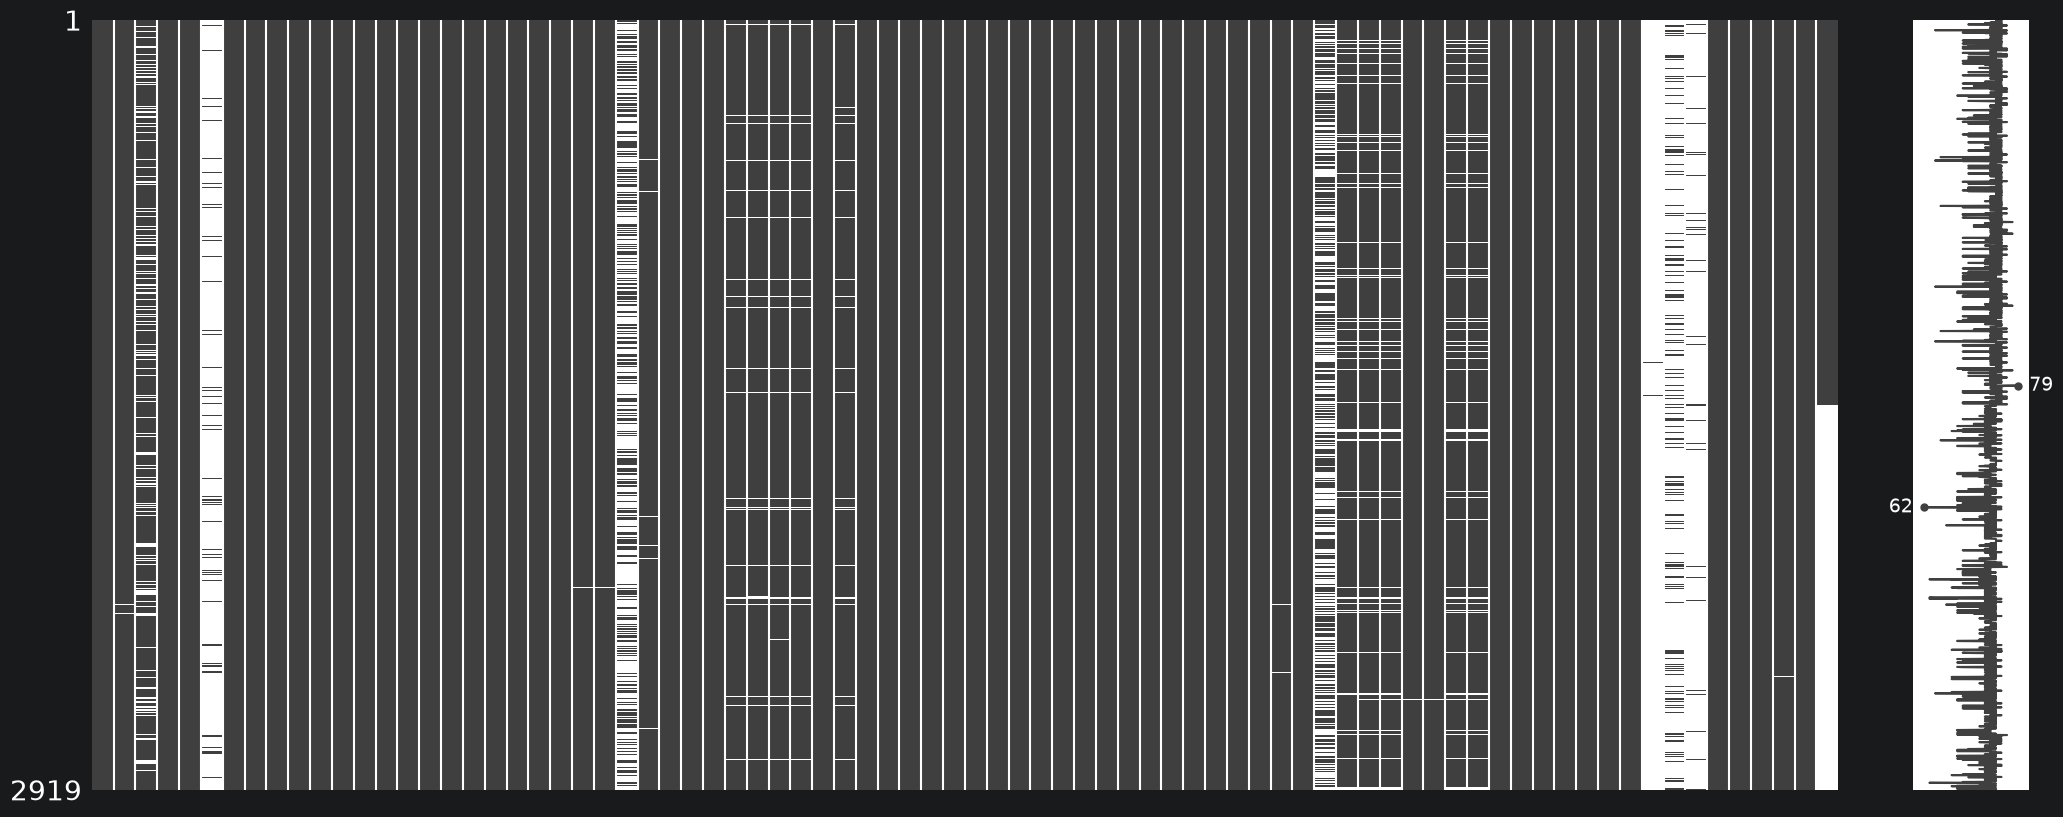

In [3]:
#1.探索性数据分析
##1.1统计缺失值与缺失值可视化（Misingno可视化缺失数据）
train_lost_imformation=train.isna().mean().sort_values(ascending=False).head(20)
test_lost_imformation=test.isna().mean().sort_values(ascending=False).head(20)
lost_imformation_combat=pd.concat([train_lost_imformation,test_lost_imformation],axis=1)
print(lost_imformation_combat)

msno.matrix(data)


In [4]:
##1.2数据类型统计
for x in [train,test,data]:
 type=x.dtypes.value_counts()
 print(type)

##主要区别为int与float，影响不大


str        43
int64      35
float64     3
Name: count, dtype: int64
str        43
int64      26
float64    11
Name: count, dtype: int64
str        43
int64      25
float64    12
Name: count, dtype: int64


In [5]:
#1.3数据分布统计与对比
#特征可分类为（1）数值型特征：连续性与离散型（定义len(col.unique())小于30为离散型特征）
#          (2)非数值型特征
features=data.drop(["SalePrice"],axis=1)
numerical_features=[col for col in features.select_dtypes(include=[int,float])]
catagorical_features=[col for col in features.select_dtypes(include=[object])]
continupou_features=[col for col in numerical_features if len(features[col].unique())>=25]
discrete_features=[col for col in numerical_features if len(features[col].unique()) < 25]
print(f"numerical_features: {len(numerical_features)}")
print(f"discrete_features: {len(discrete_features)}")
print(f"catagorical_features: {len(catagorical_features)}")
print(f"continupous_features: {len(continupou_features)}")

print(len(data["3SsnPorch"].unique()))

numerical_features: 36
discrete_features: 15
catagorical_features: 43
continupous_features: 21
31


C:\Users\zyb\AppData\Local\Temp\ipykernel_12536\4286100606.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catagorical_features=[col for col in features.select_dtypes(include=[object])]


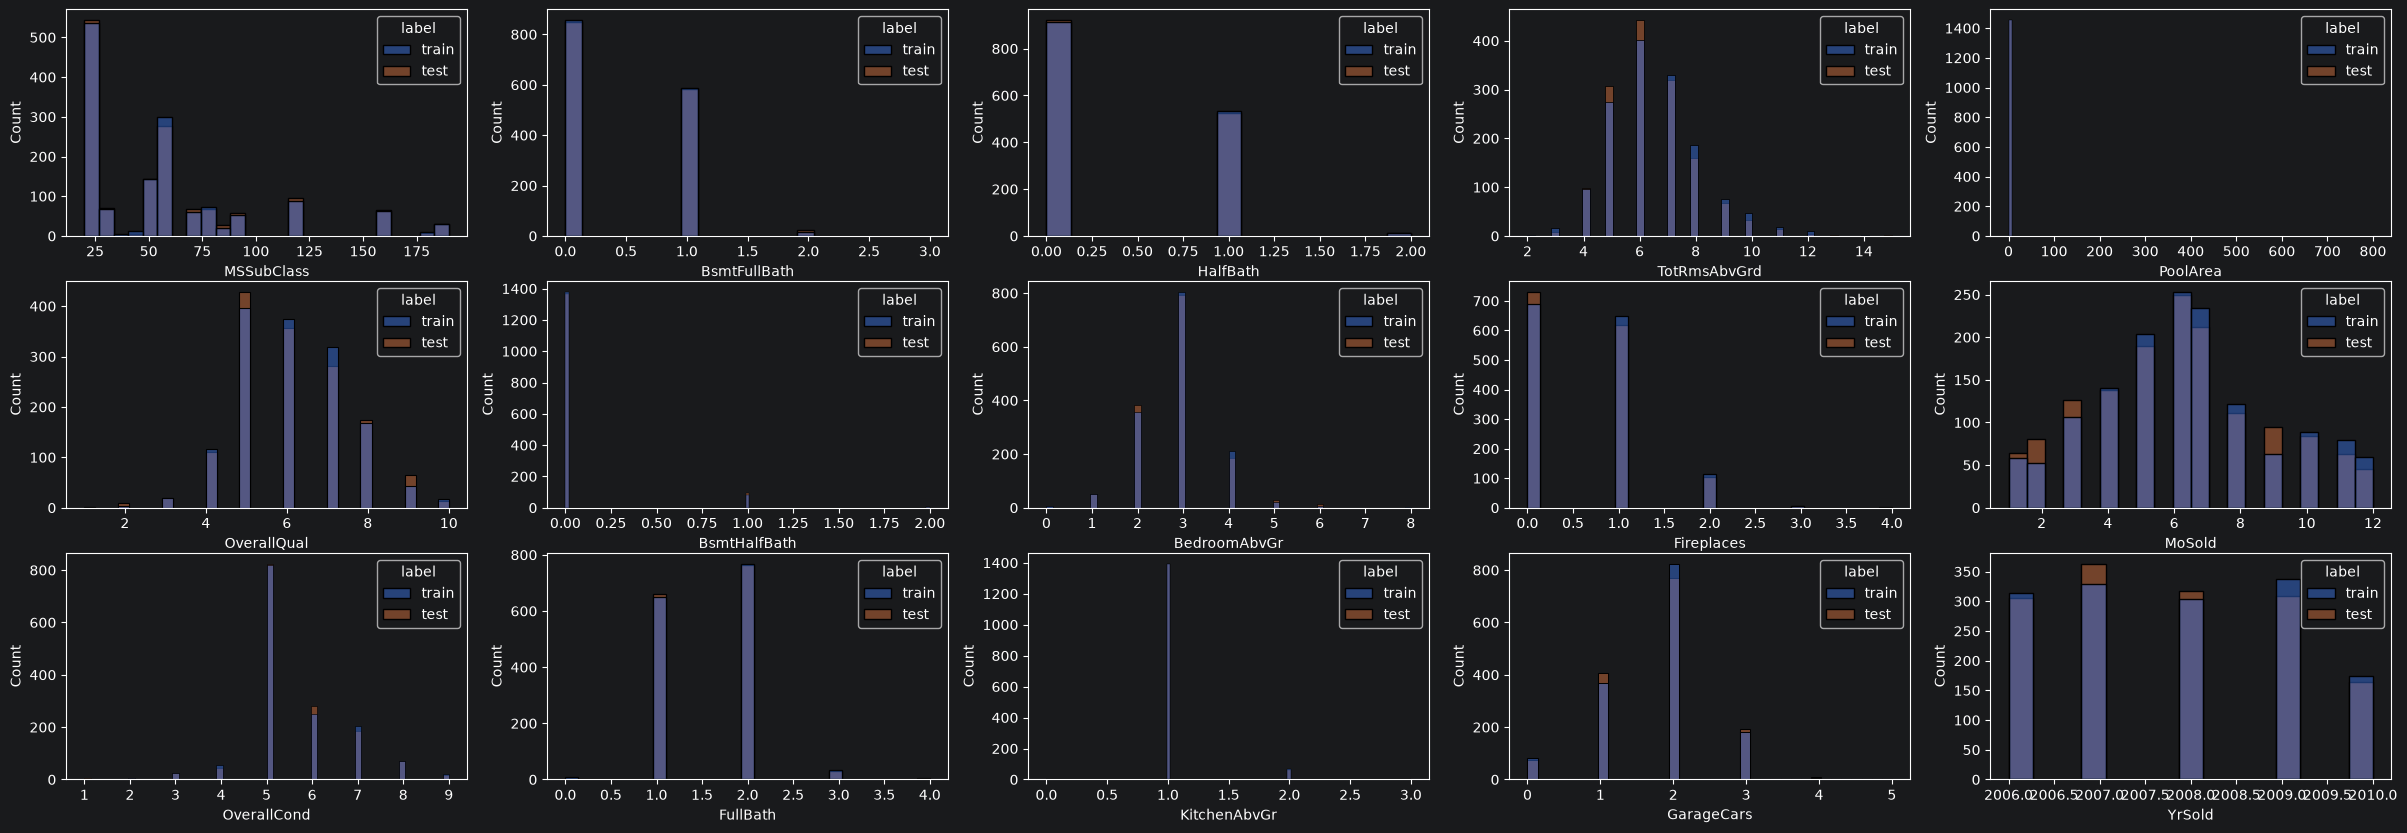

In [6]:

##1.3.1对比离散数据
#插入label标签标识训练数据与测试数据
data["label"]="test"
data.loc[:1459, "label"] = "train"

##绘制train与test对比的条形统计图
f,axes=plt.subplots(3,5,figsize=(30,10),sharex=False)
for i,feature in enumerate(discrete_features):
    sns.histplot(data=data,x=feature,hue="label",ax=axes[i%3,i//3])

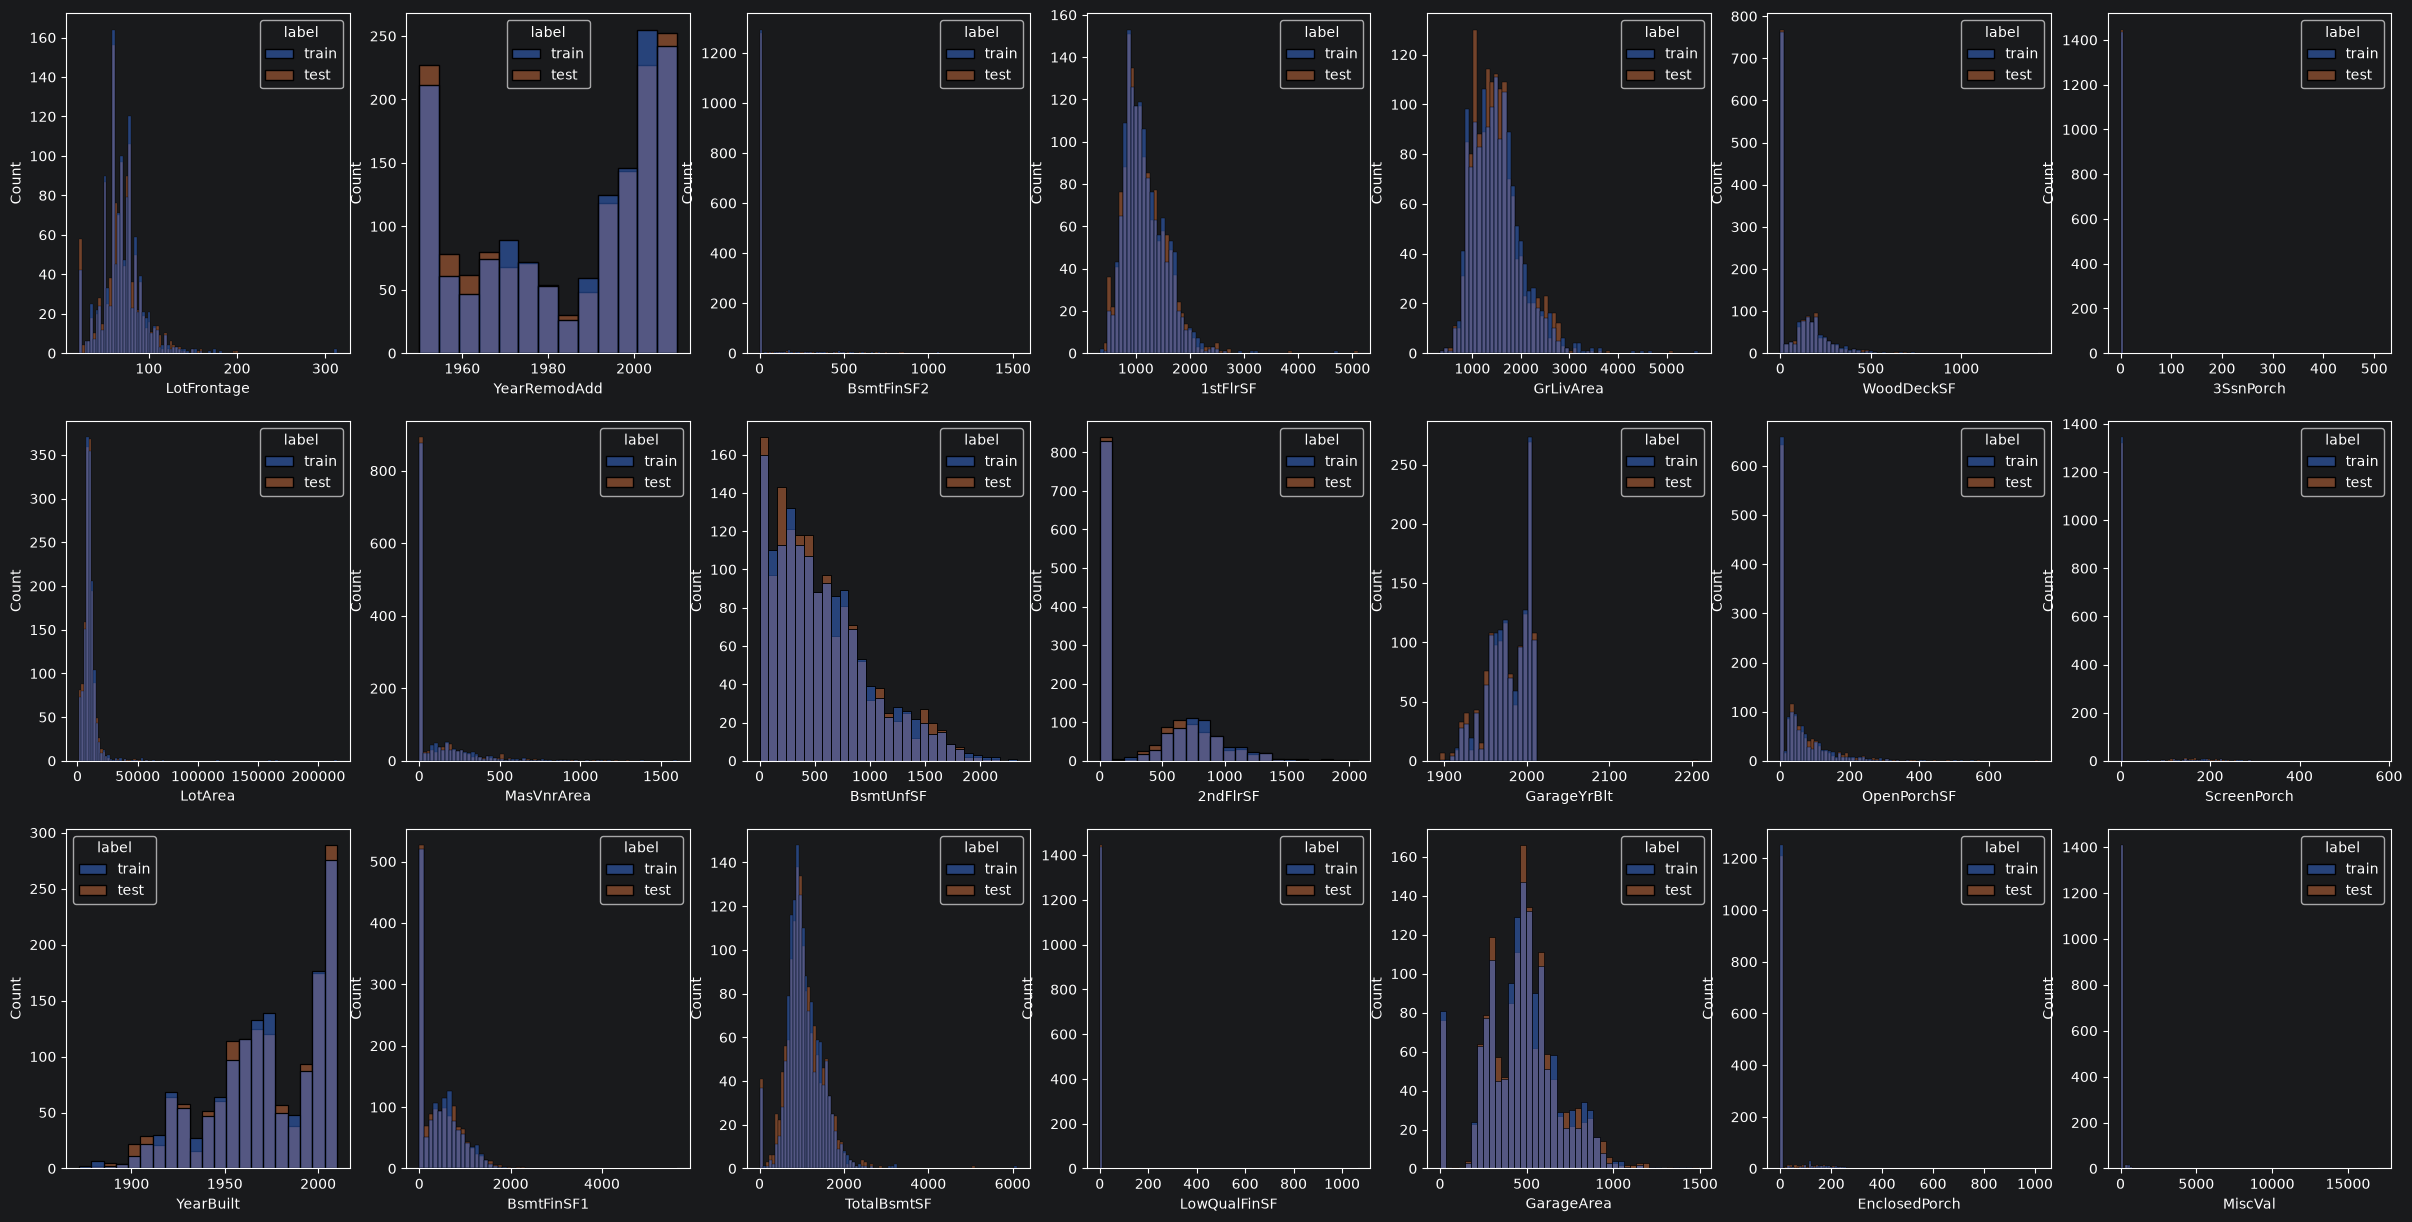

In [7]:

##1.3.2对比连续数据
f,axes=plt.subplots(3,7,figsize=(30,15),sharex=False)
for i,feature in enumerate(continupou_features):
    sns.histplot(data=data,x=feature,hue="label",ax=axes[i%3,i//3])




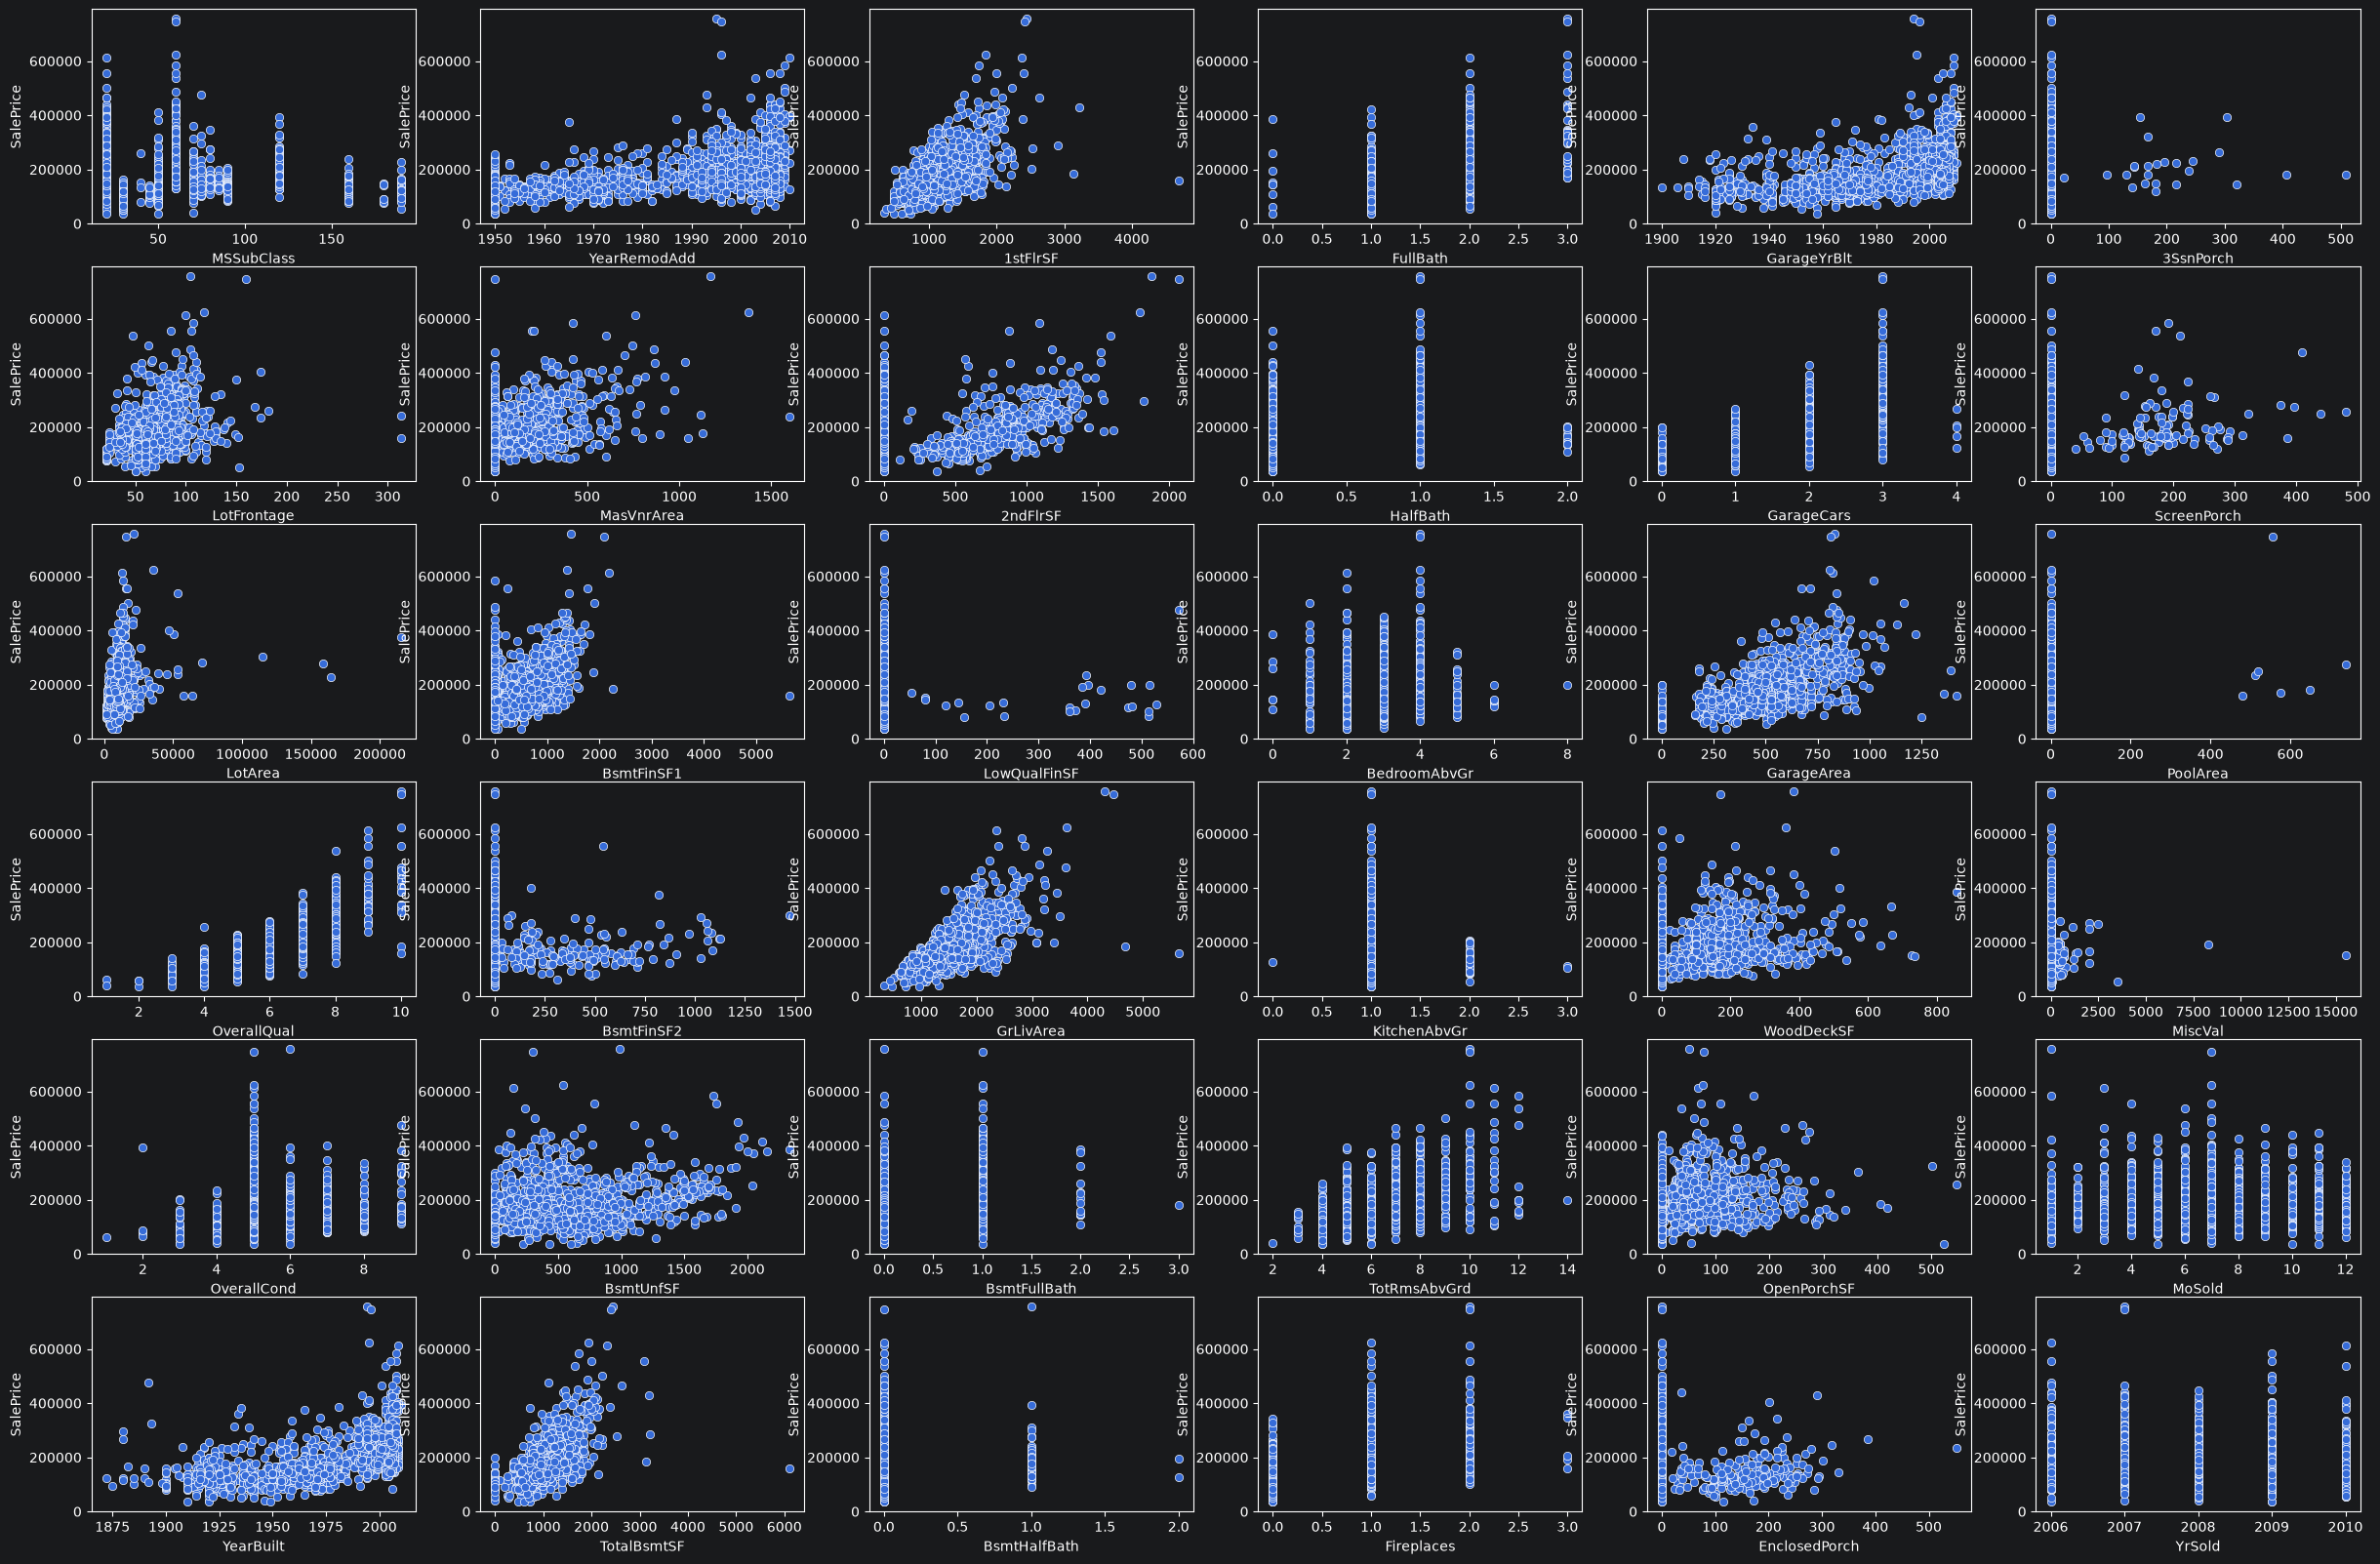

In [8]:
#1.3.3查看数据型特征与房价之间的线性关系强弱
#采用散点图进行可视化呈现
f,axes=plt.subplots(6,6,figsize=(30,20),sharex=False)
for i,feature in enumerate(numerical_features):
    sns.scatterplot(data=train,x=feature,y="SalePrice",ax=axes[i%6,i//6])

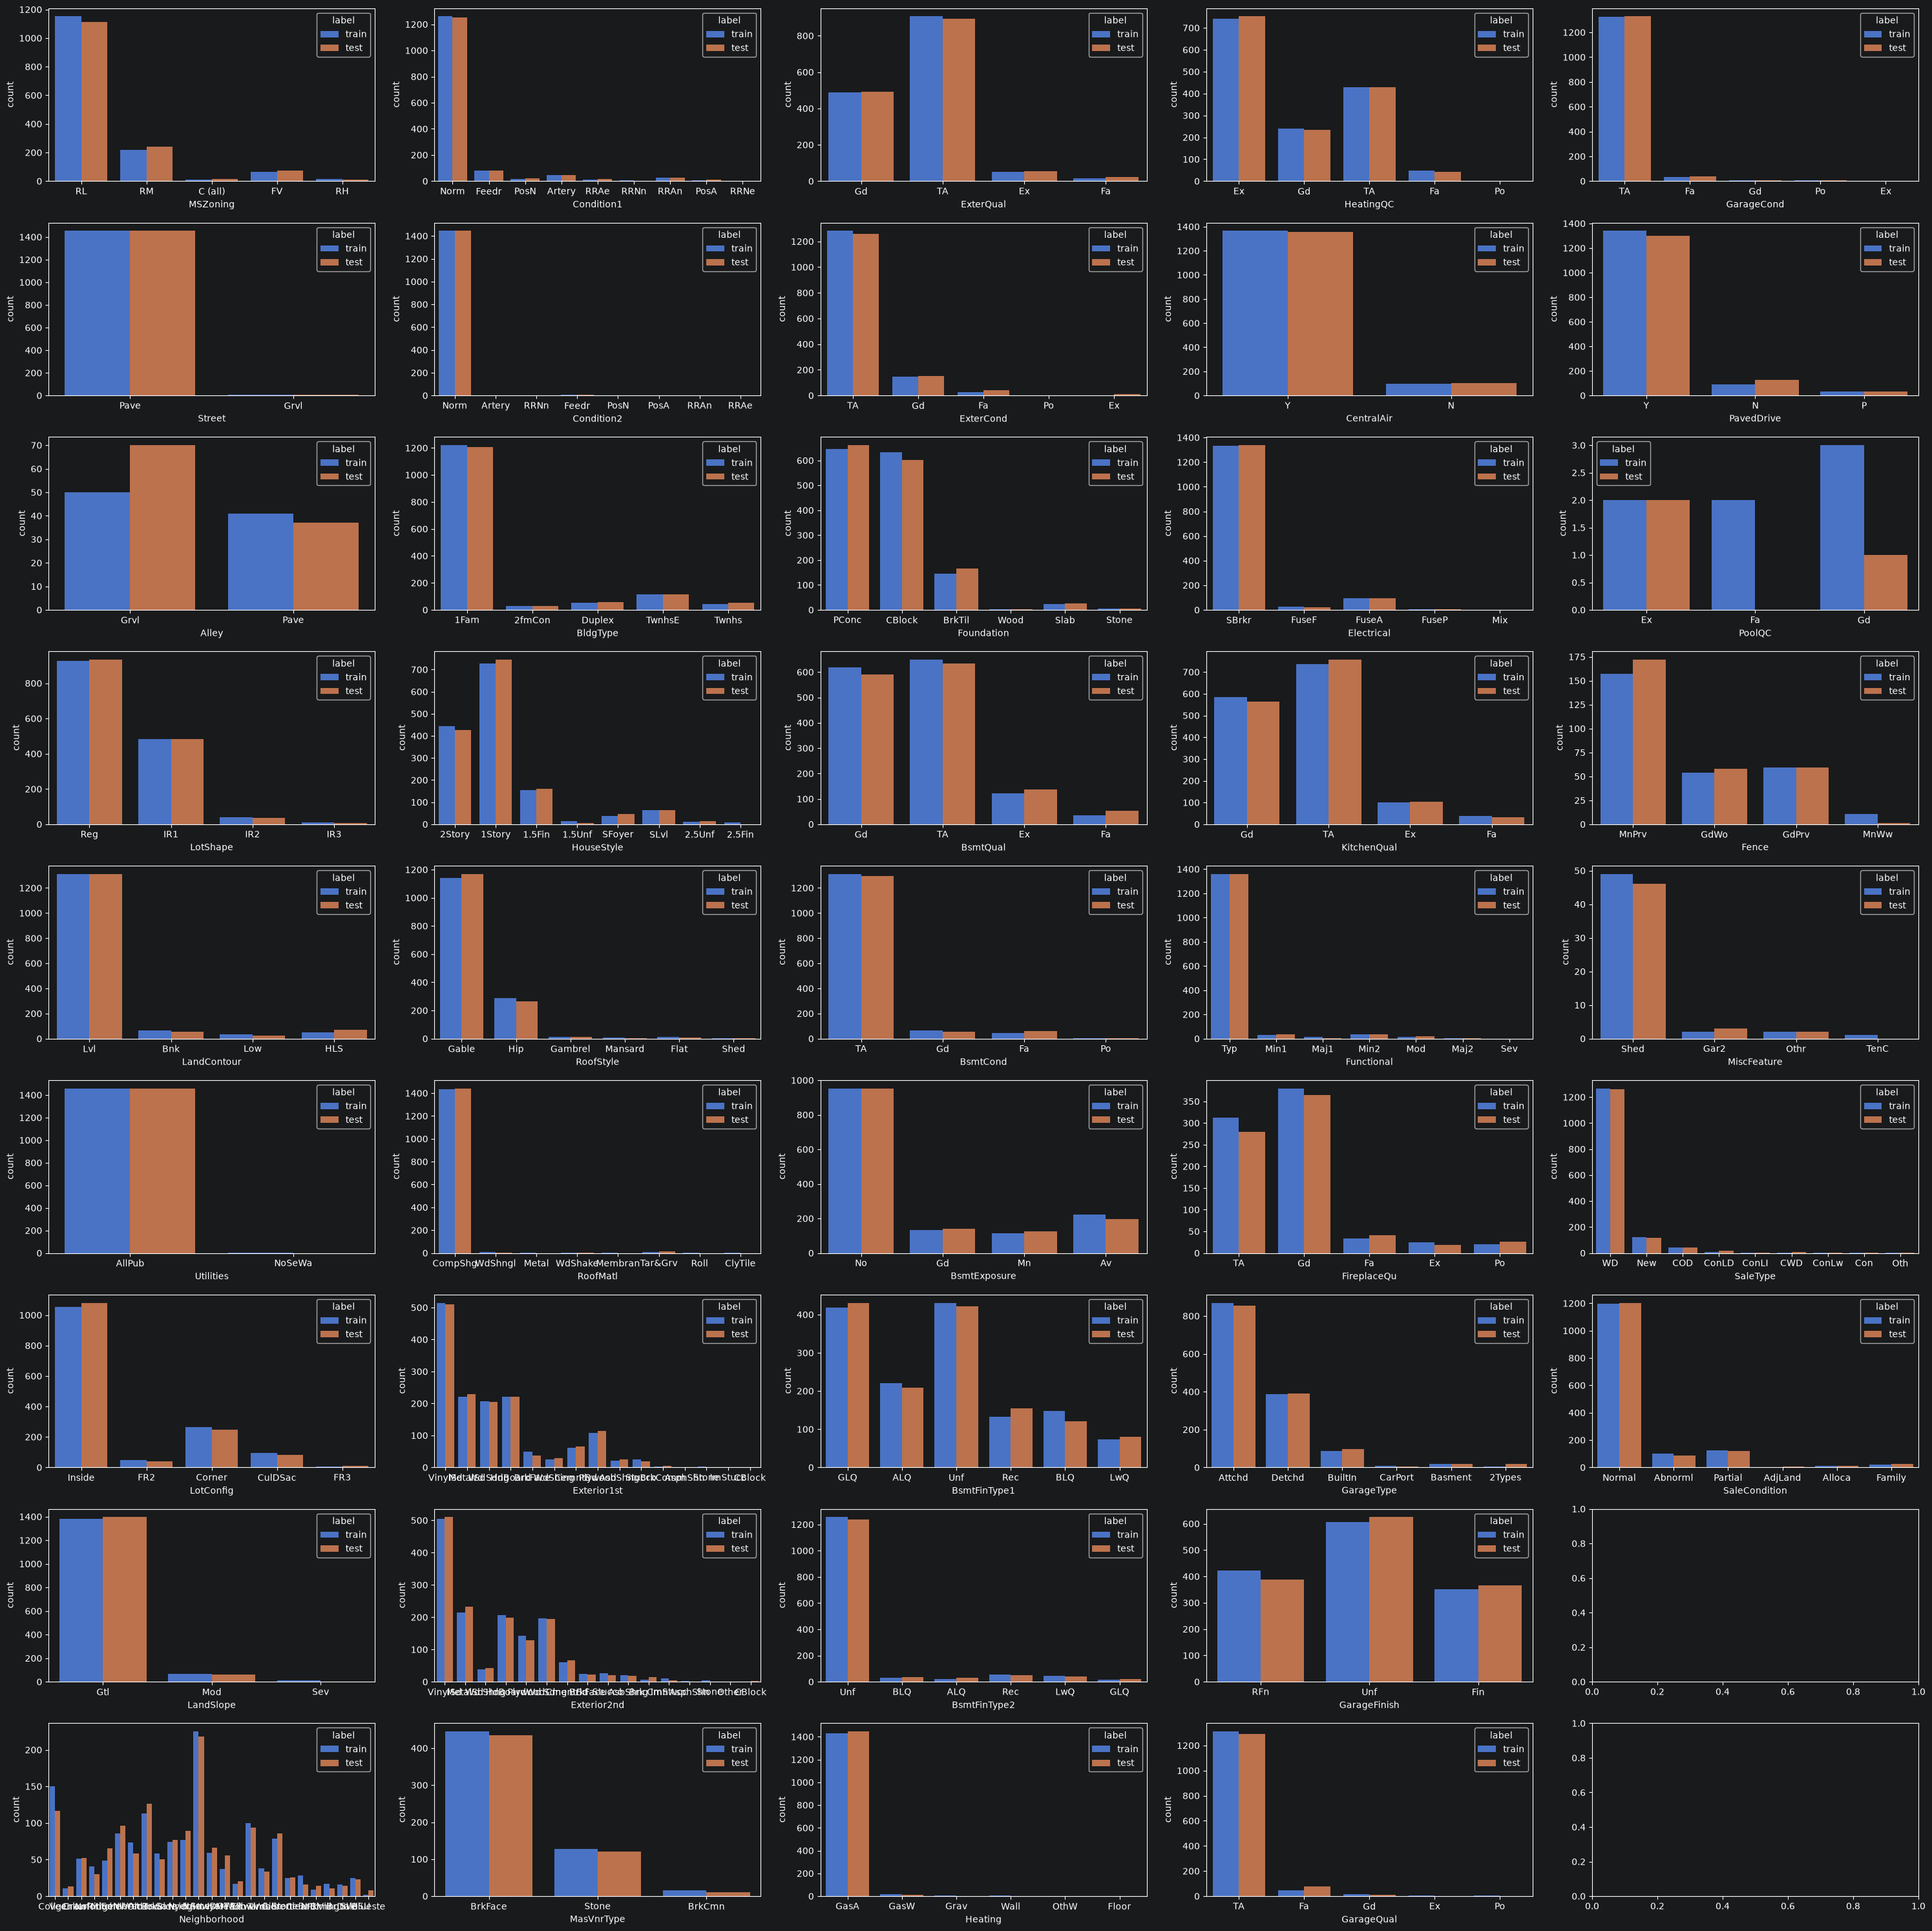

In [9]:
#1.3.4非数值型特征对比分析
f,axes=plt.subplots(9,5,figsize=(30,30),sharex=False)
for i,feature in enumerate(catagorical_features):
    sns.countplot(data=data,x=feature,hue="label",ax=axes[i%9,i//9])
plt.tight_layout()
plt.show()

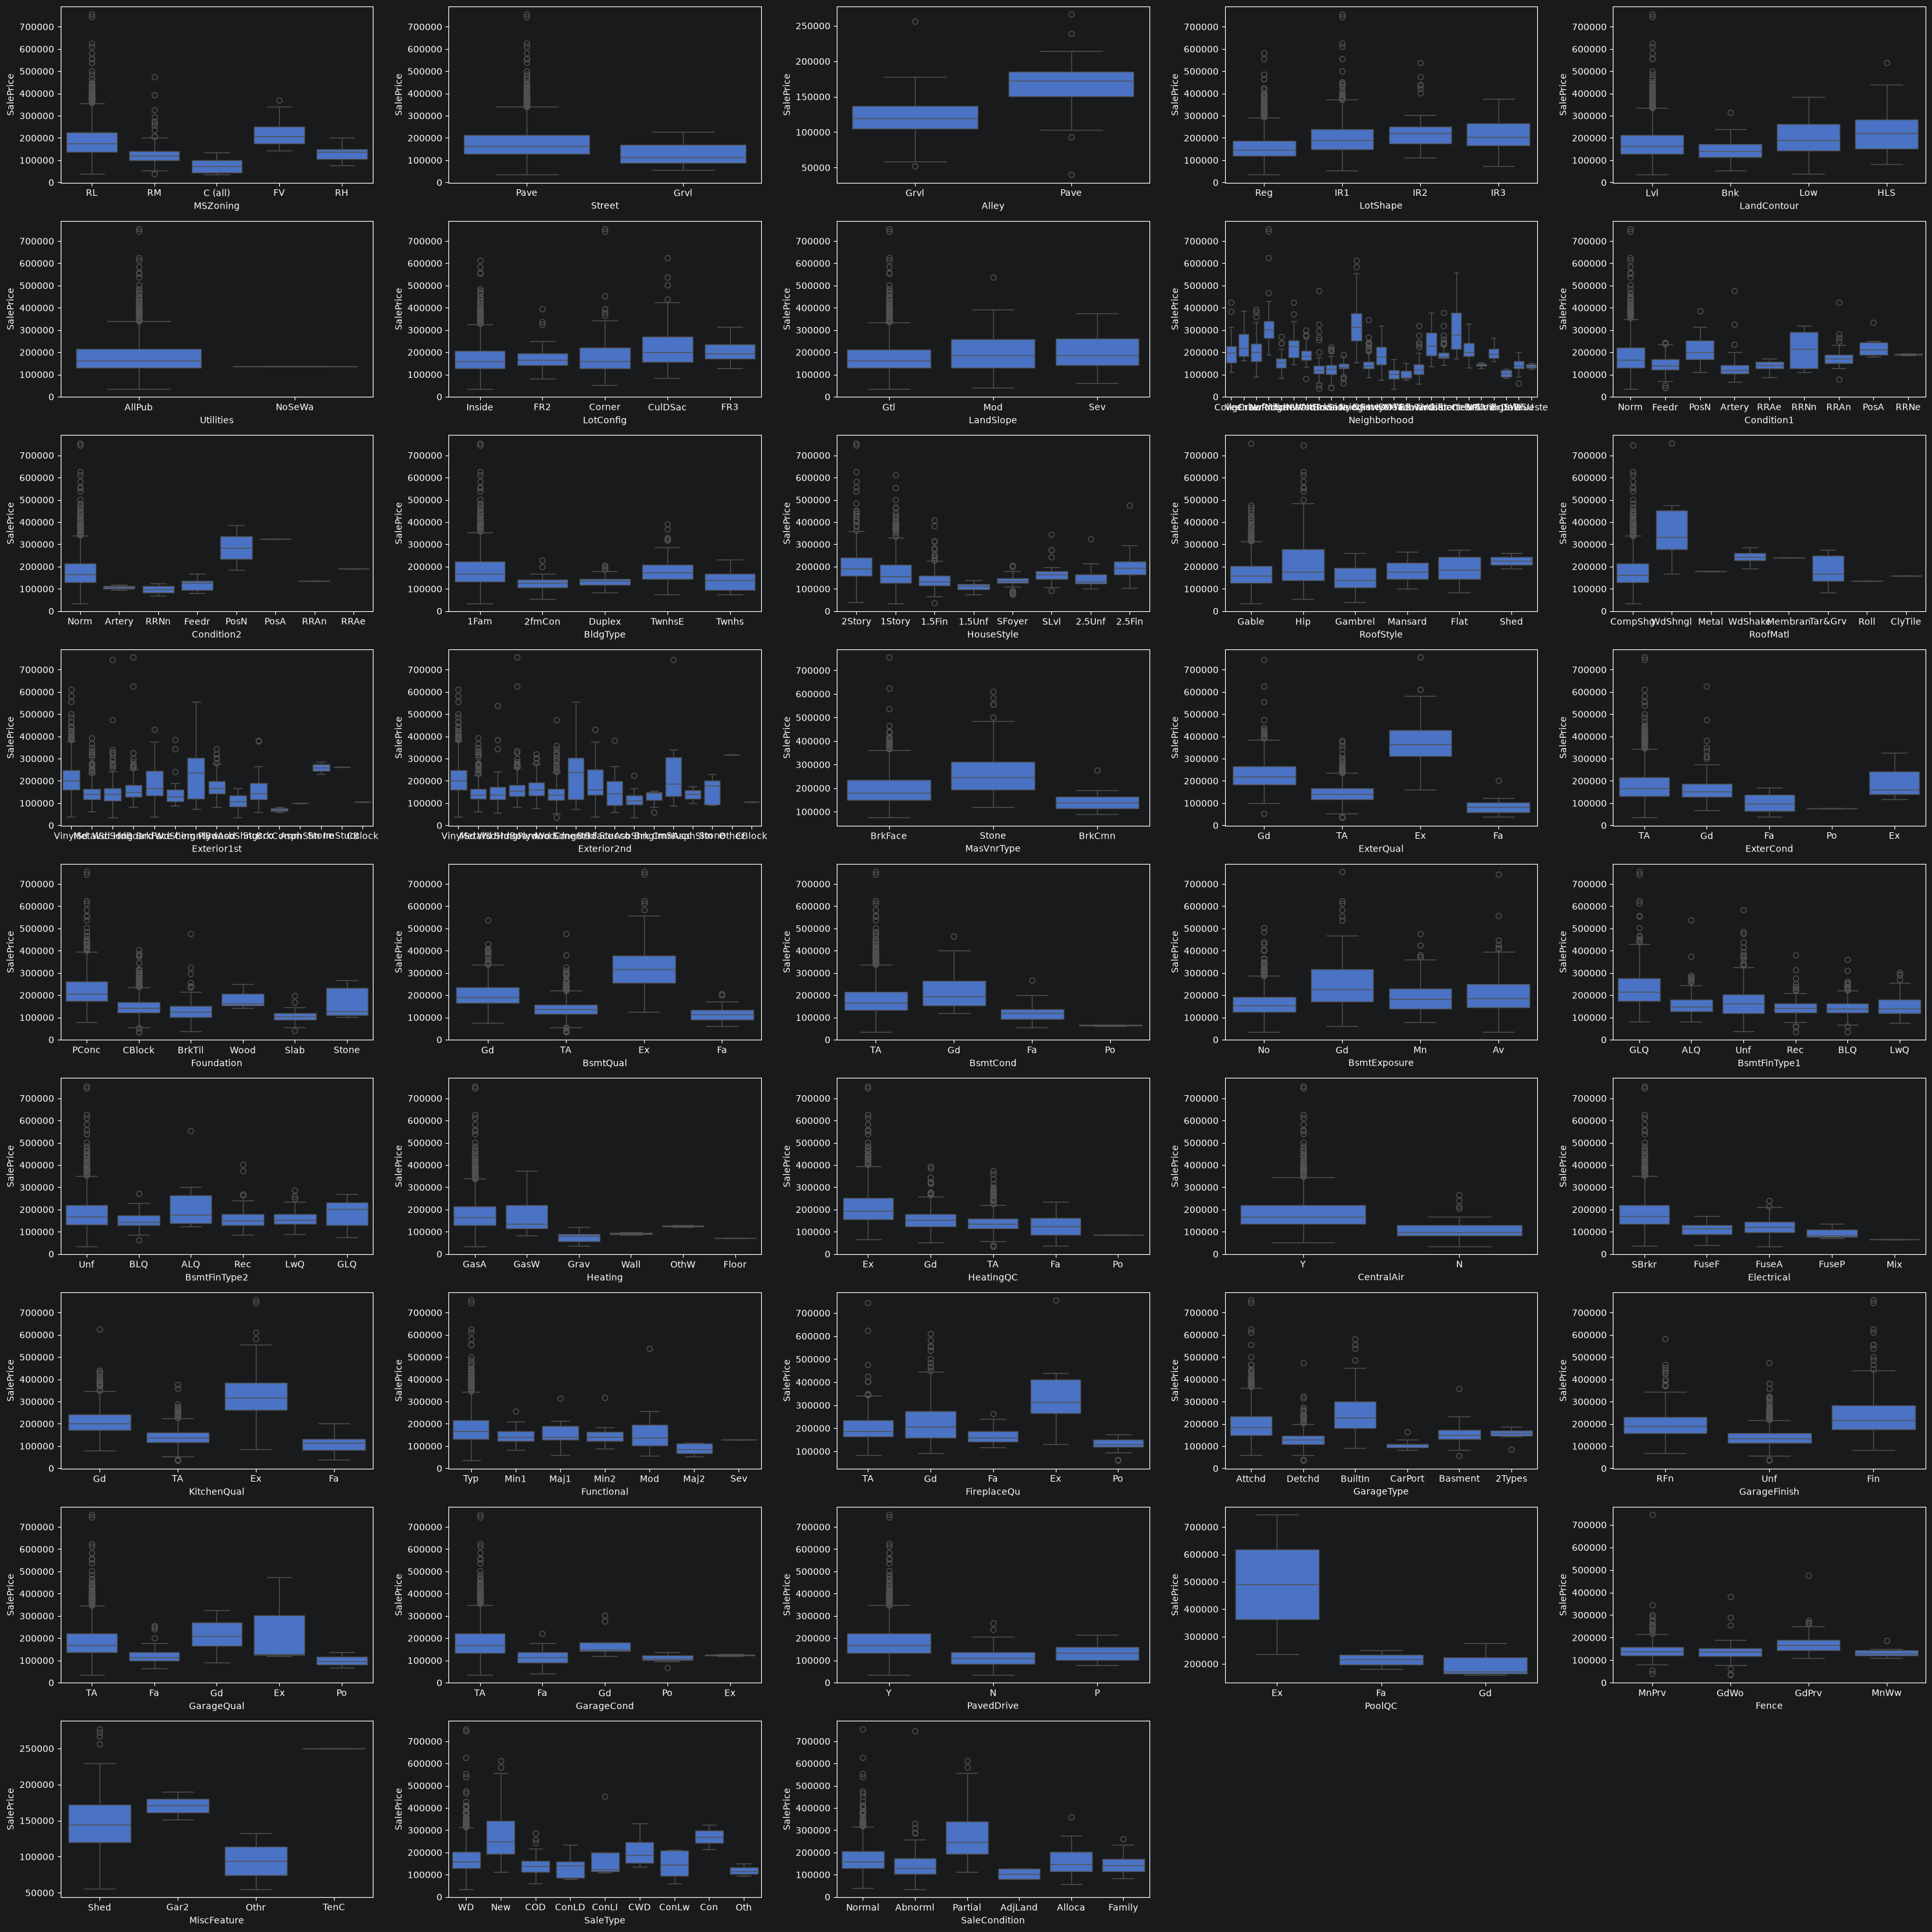

In [10]:
#1.3.5查看非数值型数据的分布(取值为SalePrice)
plt.figure(figsize=(30,30))
for i,feature in enumerate(catagorical_features):
    plt.subplot(9,5,i+1)
    sns.boxplot(data=data,x=feature,y="SalePrice")

plt.tight_layout()
plt.show()

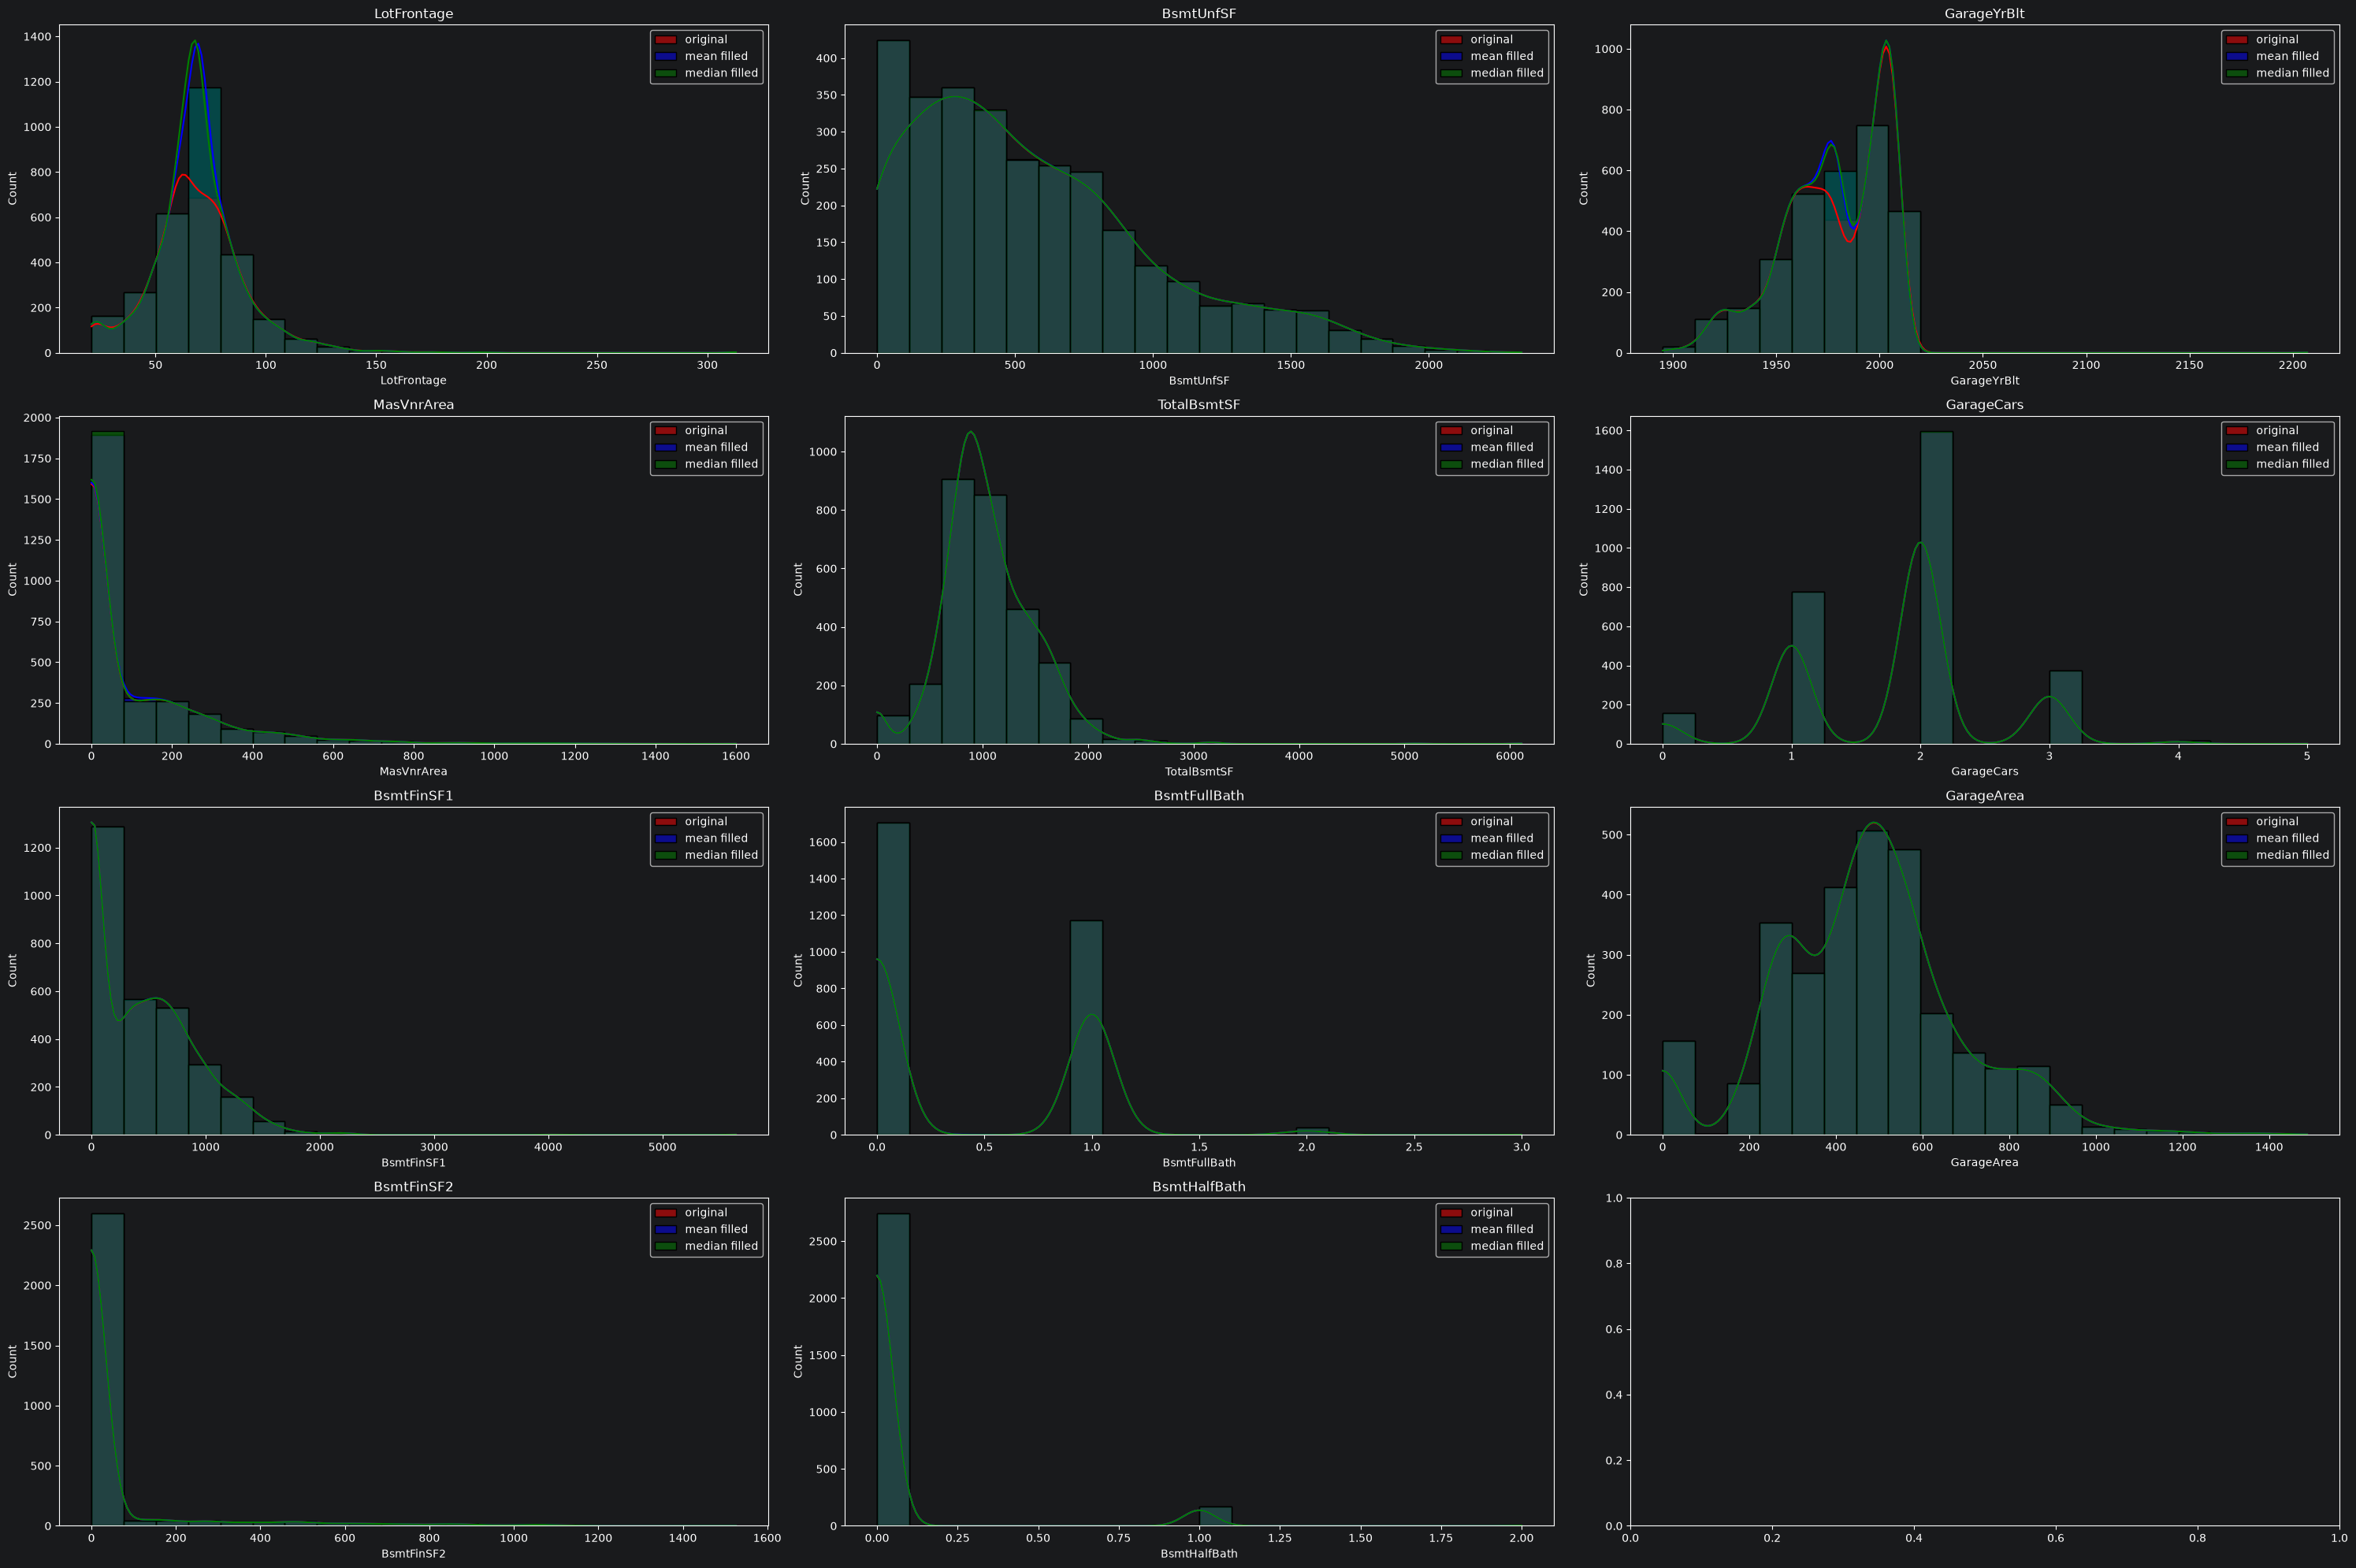

In [11]:
#数值型填充
null_features_numerical = [col for col in data.columns
                           if data[col].isnull().sum() > 0
                           and col  in numerical_features]

f,axes=plt.subplots(4,3,figsize=(30,20),sharex=False)
for i,feature in enumerate(null_features_numerical):
    ax = axes[i % 4, i // 4]
    sns.histplot(data[feature].dropna(), bins=20, kde=True,color="red",label="original",alpha=0.5,ax=ax)
    sns.histplot(data[feature].fillna(data[feature].mean()), bins=20, kde=True,color="blue",label="mean filled",alpha=0.5,ax=ax)
    sns.histplot(data[feature].fillna(data[feature].median()), bins=20, kde=True,color="green",label="median filled",alpha=0.5,ax=ax)
    ax.set_title(feature)
    ax.legend()

plt.tight_layout()
plt.show()


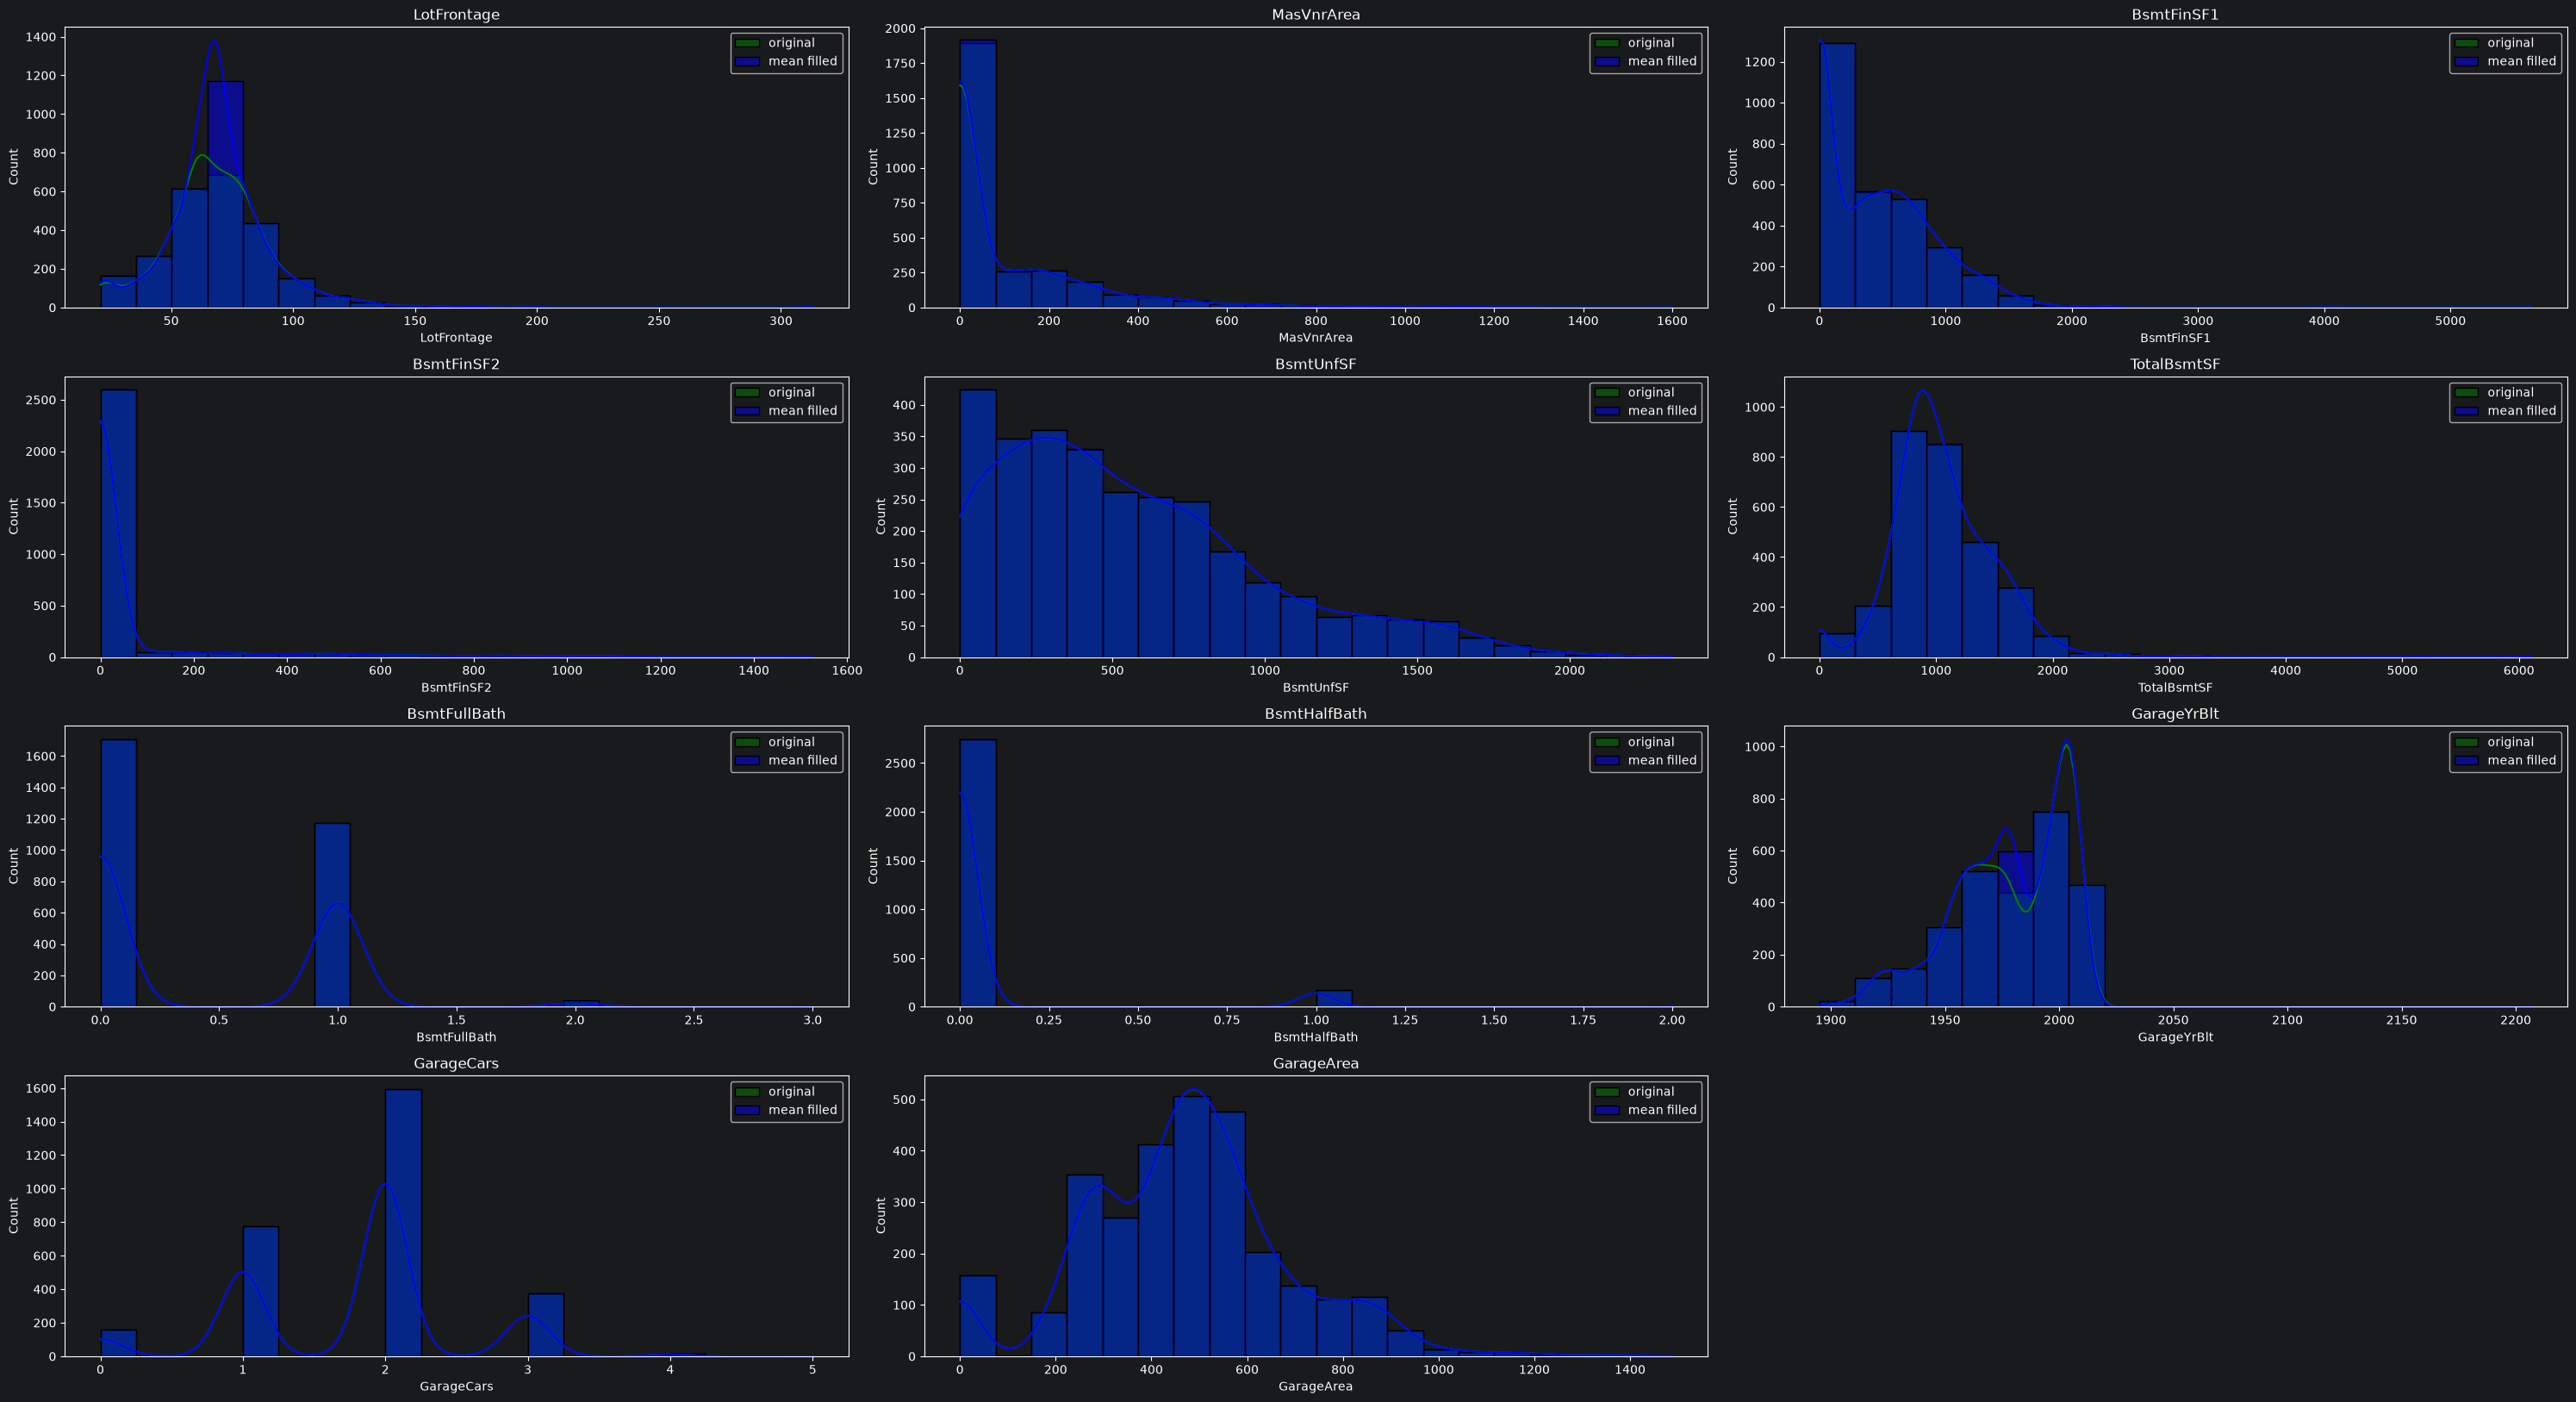

In [12]:
null_features_numerical = [col for col in data.columns
                           if data[col].isnull().sum() > 0
                           and col  in numerical_features]

plt.figure(figsize=(30, 20))

for i, var in enumerate(null_features_numerical):
    plt.subplot(5, 3, i + 1)

    # 原始数据（忽略 NaN）
    sns.histplot(data[var].dropna(), bins=20, kde=True,
                 color="green", label="original", alpha=0.5)

    # 均值填充后的数据
    filled = data[var].fillna(data[var].median())
    sns.histplot(filled, bins=20, kde=True,
                 color="blue", label="mean filled", alpha=0.5)

    plt.title(var)
    plt.legend()

plt.tight_layout()
plt.show()

['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold']


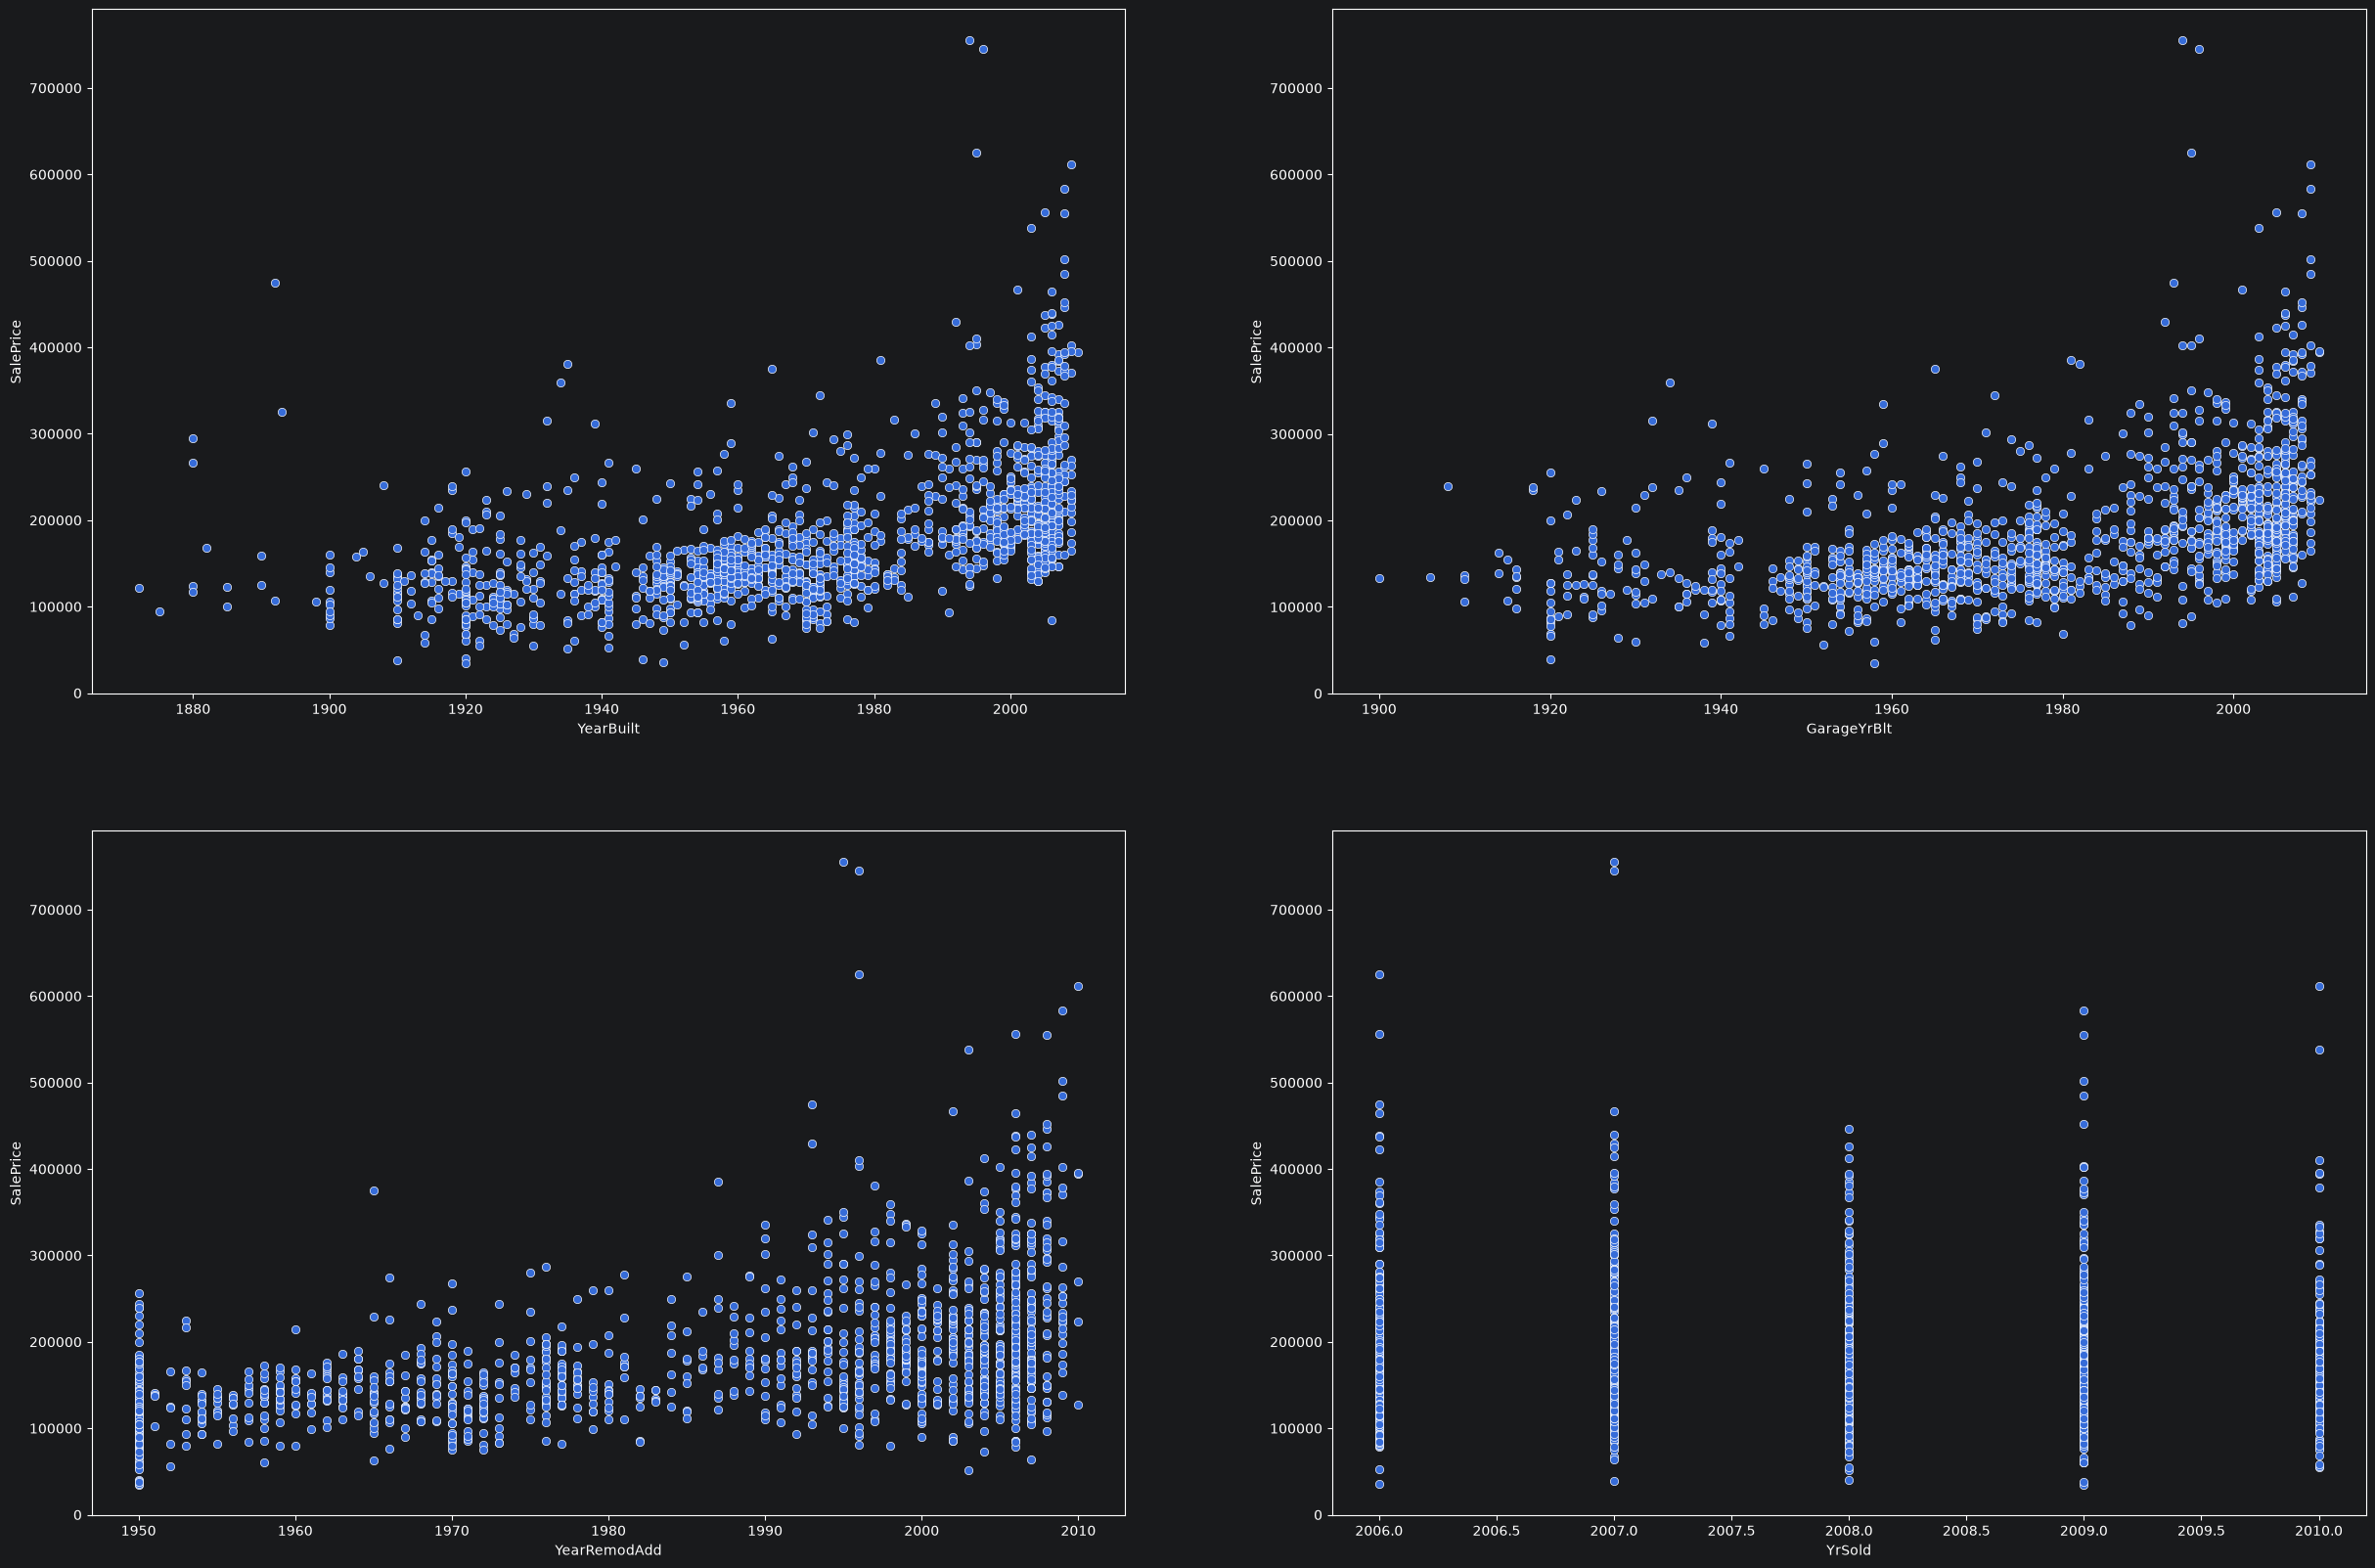

In [13]:
#1.5时序特征分析
year_feature=[col for col in data.columns if "Yr" in col or "Year" in col]
print(year_feature)

f,axes=plt.subplots(2,2,figsize=(30,20),sharex=False)
for i,year_feature in enumerate(year_feature):
    ax = axes[i % 2, i // 2]
    sns.scatterplot(data=train,x=year_feature,y="SalePrice",ax=ax)

<Axes: >

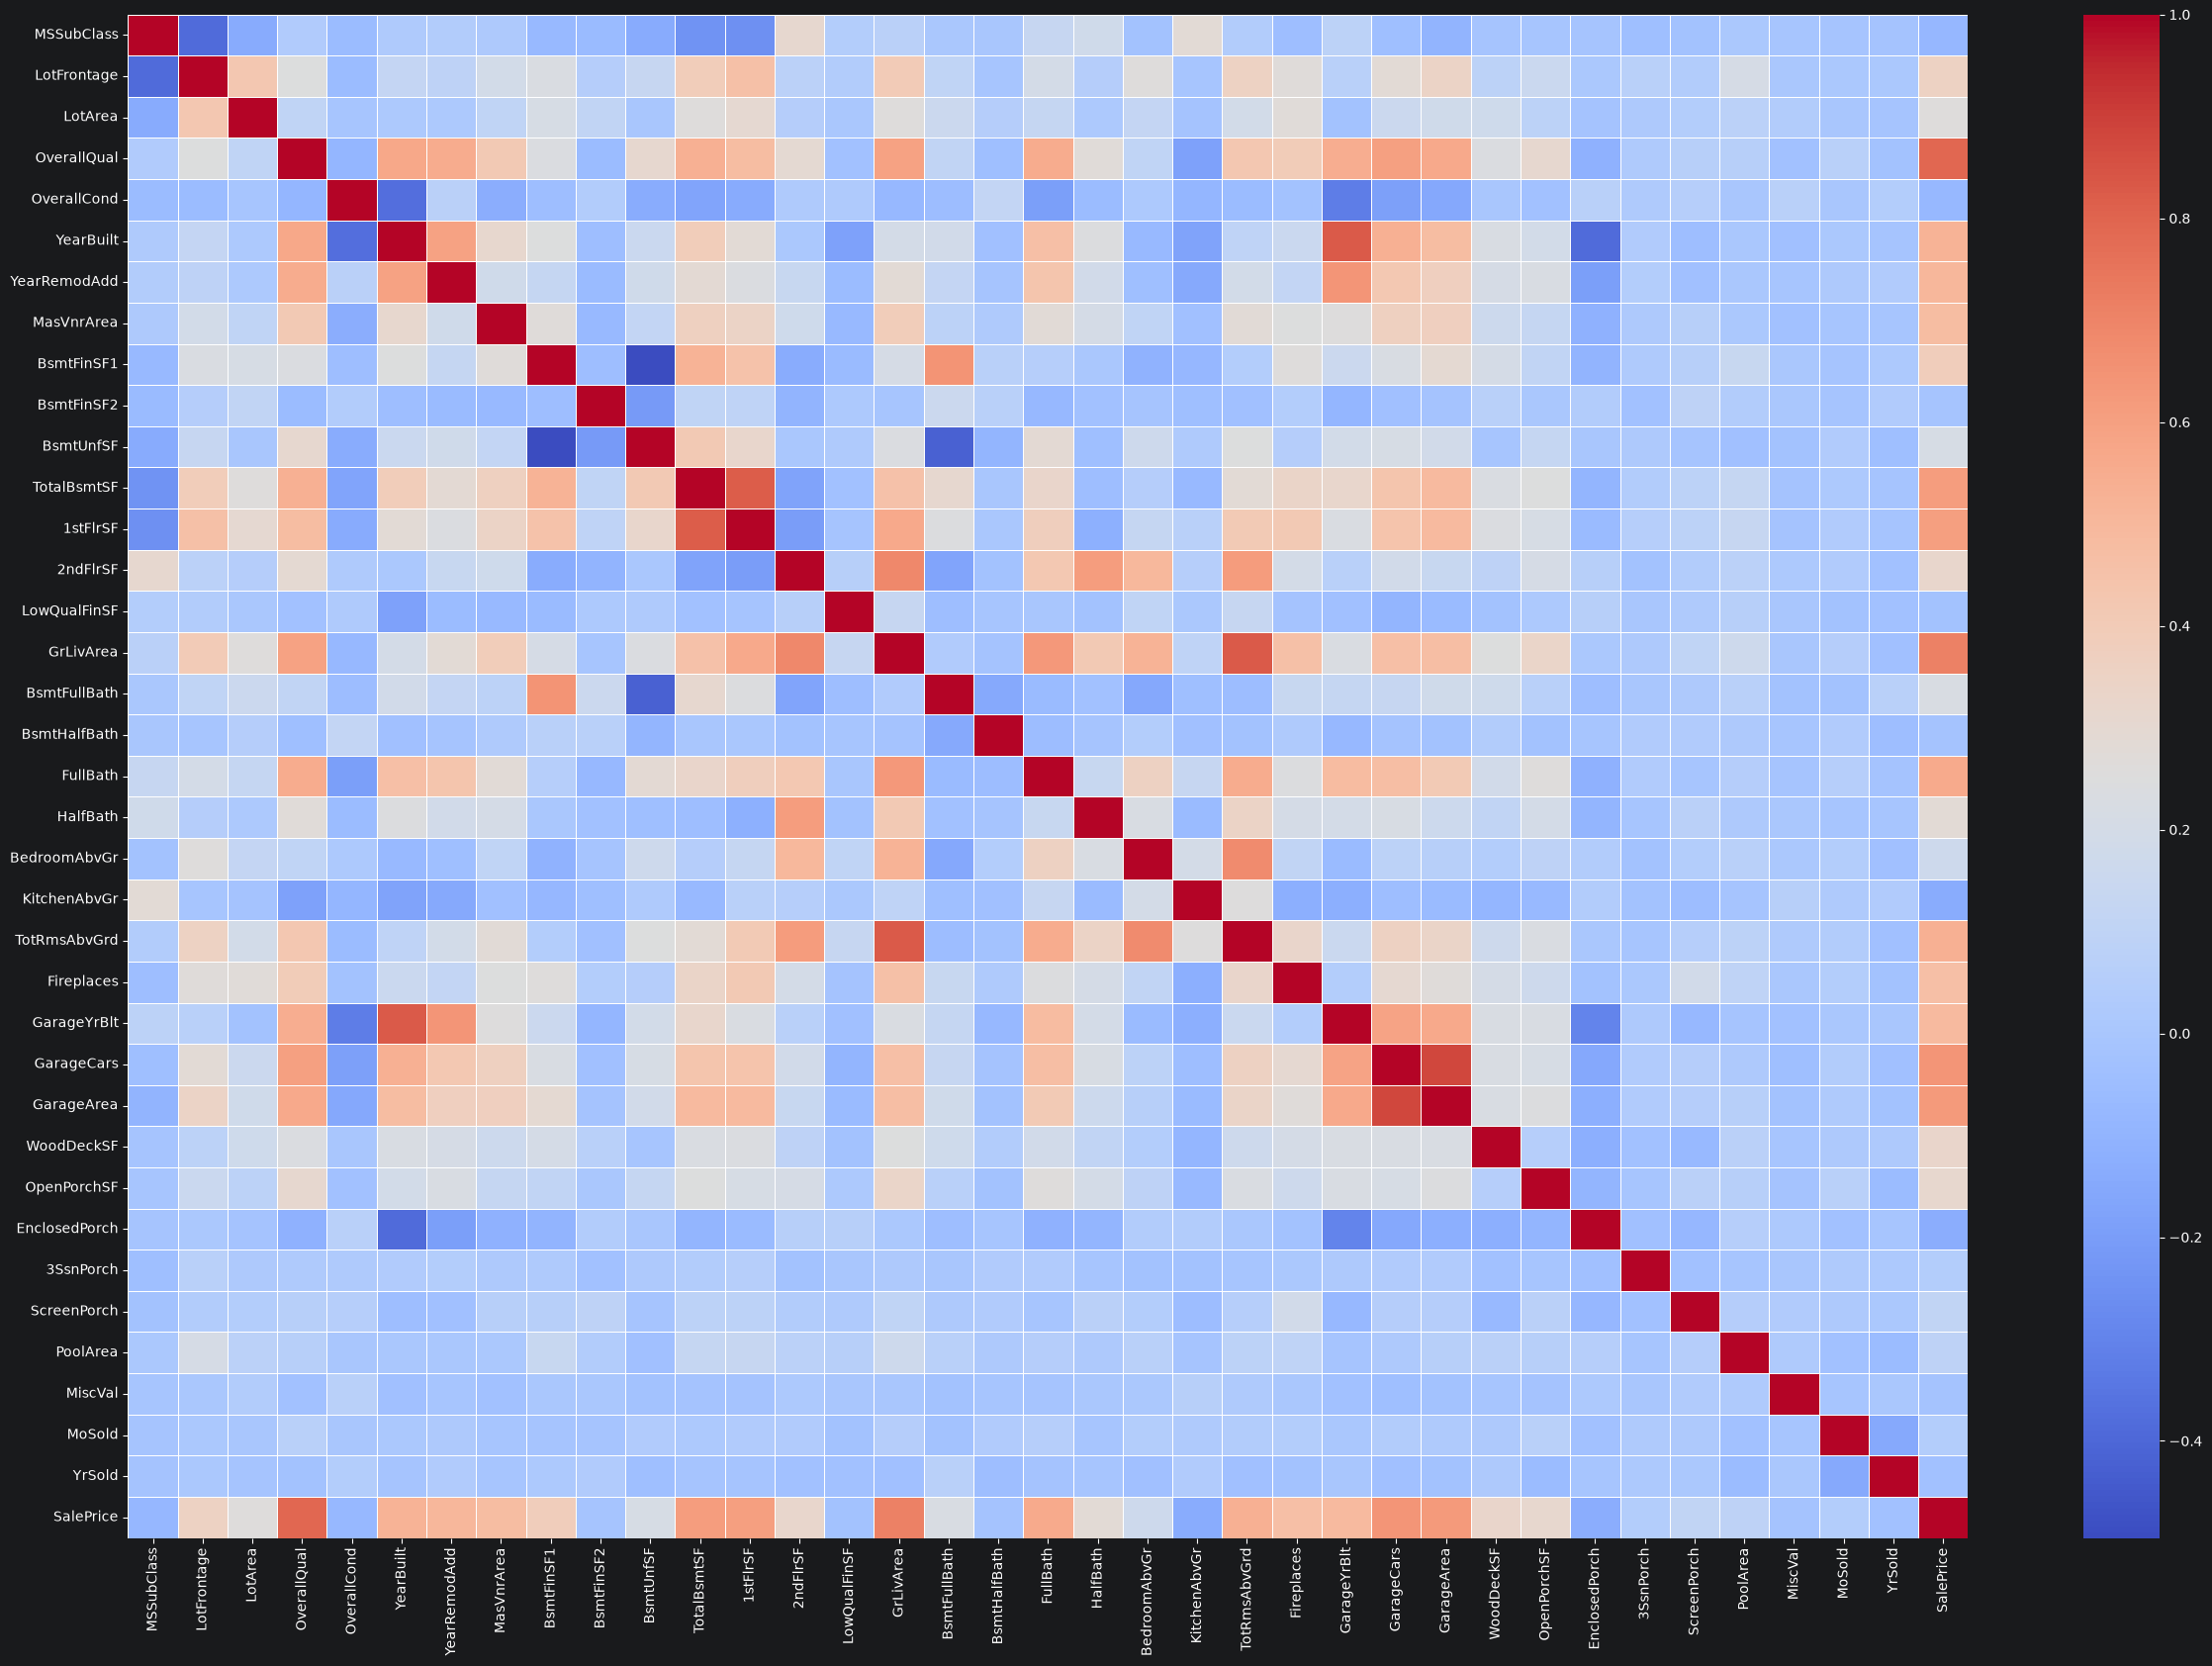

In [14]:
#1.6用热力图分析数值型类型之间的相关性
plt.figure(figsize=(30,20))
numerical_column=numerical_features+["SalePrice"]
sns.heatmap(train[numerical_column].corr(),cmap="coolwarm",linewidths=.5)


In [15]:
#2.数据处理
#2.1 SalePrice的正态化处理
orifinal_skew=data["SalePrice"].skew()
print(orifinal_skew)
##偏度1.8，过于偏离正态分布，考虑采用取对的方式减弱极端值影响
normaility_skew=np.log1p(data["SalePrice"]).skew()
#也即
normaility_skew=np.log(1+data["SalePrice"]).skew()
print(normaility_skew)
##偏度为0.12，接近于正态分布


1.8828757597682129
0.12134661989685333


In [16]:
#2.2 非数值型特征处理
#2.2.1 融合特征值
def find_all(data, categorical_features):
    """找出所有需要合并的 (特征, 低频值列表)"""
    result = []
    for feature in categorical_features:
        counts = data[feature].value_counts()
        low_values = counts[counts < 20].index.tolist()
        if low_values:
            result.append((feature, low_values))
    return result
print(find_all(data, catagorical_features))

def merge(data, feature, values):
    mask = data[feature].isin(values)
    data.loc[mask, feature] = "others"

# 一次性处理所有
for feature, values in find_all(data, catagorical_features):
    merge(data, feature, values)



#2.2.2 非数值型数据缺失值填充
#观察缺失值数量多的使用None填充，缺失值数量少的使用众数填充
highlose_catagorice=[col for col in catagorical_features if (data[col].isna().sum())>100]
lowlose_catagorice=[col for col in catagorical_features if 0<(data[col].isna().sum())<=100]

for col  in highlose_catagorice  :
    data[col]=data[col].fillna("None")


for col in lowlose_catagorice :
    data[col]=data[col].fillna(data[col].mode()[0])


[('Street', ['Grvl']), ('LotShape', ['IR3']), ('Utilities', ['NoSeWa']), ('LotConfig', ['FR3']), ('LandSlope', ['Sev']), ('Neighborhood', ['Blueste']), ('Condition1', ['RRNn', 'RRNe']), ('Condition2', ['Feedr', 'Artery', 'PosN', 'PosA', 'RRNn', 'RRAn', 'RRAe']), ('HouseStyle', ['1.5Unf', '2.5Fin']), ('RoofStyle', ['Mansard', 'Shed']), ('RoofMatl', ['WdShake', 'WdShngl', 'Metal', 'Membran', 'Roll', 'ClyTile']), ('Exterior1st', ['BrkComm', 'AsphShn', 'Stone', 'CBlock', 'ImStucc']), ('Exterior2nd', ['ImStucc', 'Stone', 'AsphShn', 'CBlock', 'Other']), ('ExterCond', ['Ex', 'Po']), ('Foundation', ['Stone', 'Wood']), ('BsmtCond', ['Po']), ('Heating', ['Grav', 'Wall', 'OthW', 'Floor']), ('HeatingQC', ['Po']), ('Electrical', ['FuseP', 'Mix']), ('Functional', ['Maj1', 'Maj2', 'Sev']), ('GarageType', ['CarPort']), ('GarageQual', ['Po', 'Ex']), ('GarageCond', ['Gd', 'Po', 'Ex']), ('PoolQC', ['Ex', 'Gd', 'Fa']), ('Fence', ['MnWw']), ('MiscFeature', ['Gar2', 'Othr', 'TenC']), ('SaleType', ['CWD', 'C

In [17]:
#2.3 数值型特征处理
##2.3.1数值型数据的缺失值填充

for col in discrete_features :
    data[col]=data[col].fillna(data[col].mode()[0])
for col in continupou_features :
    data[col]=data[col].fillna(data[col].mean())



In [ ]:
#3 数据集编码与切分
data.drop("label", axis=1, inplace=True)
data=pd.get_dummies(data, columns=catagorical_features,dtype=int)
new_train=((data.iloc[:len(train),:])).reset_index()

new_test=(data.iloc[len(train):,:]).reset_index()
X_train=new_train.drop("SalePrice",axis=1)
y_train=new_train["SalePrice"]
X_test=new_test.drop("SalePrice",axis=1)
y_train_log = np.log1p(y_train)

In [19]:
print(X_train.head)
print(y_train.isna().sum())
print(X_test.head)

<bound method NDFrame.head of       index  MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  \
0         0          60         65.0     8450            7            5   
1         1          20         80.0     9600            6            8   
2         2          60         68.0    11250            7            5   
3         3          70         60.0     9550            7            5   
4         4          60         84.0    14260            8            5   
...     ...         ...          ...      ...          ...          ...   
1455   1455          60         62.0     7917            6            5   
1456   1456          20         85.0    13175            6            6   
1457   1457          70         66.0     9042            7            9   
1458   1458          20         68.0     9717            5            6   
1459   1459          20         75.0     9937            5            6   

      YearBuilt  YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  SaleType_

In [ ]:
import optuna
import xgboost
#4 建立模型并预测结果
def tune(objective):
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=10)
    params = study.best_params
    best_score = study.best_value
    return params
from xgboost import XGBRegressor
def xbg_objective(trial):
    n_estimators=trial.suggest_int("n_estimators", 50, 2000)
    max_depth=trial.suggest_int("max_depth", 2, 10)
    learning_rate=trial.suggest_float("learning_rate", 0.01, 1)
    xgboost=XGBRegressor(
      n_estimators=n_estimators,
      max_depth=max_depth,
      learning_rate=learning_rate
    )
    xgboost.fit(X_train, y_train_log)
    score=cross_val_score(xgboost,X_train, y_train_log,cv=10,scoring="neg_mean_squared_error").mean()
    return score
xbg_params=tune(xbg_objective)
xgboost=XGBRegressor(**xbg_params,random_state=1)




xgboost.fit(X_train,y_train_log)
predictions=np.expm1(xgboost.predict(X_test))
Id=test["Id"]
submission=pd.DataFrame({"Id":Id,"SalePrice":predictions})
submission.to_csv("submission.csv",index=False)
